# CRISP-DM Project: RAG-Anything for Multimodal Document Question Answering

**Course:** CMPE 255 — Data Mining  
**Methodology:** CRISP-DM  
**Framework:** RAG-Anything  
**Proposed Dataset:** MMLongBench-Doc

## Project purpose
This project investigates how a retrieval-augmented generation (RAG) system can answer questions about long documents containing text, tables, charts, and images.

The project will follow all six CRISP-DM phases: Business Understanding, Data Understanding, Data Preparation, Modeling, Evaluation, and Deployment.

In [1]:
# Install the basic libraries needed for data inspection
%pip -q install datasets pandas matplotlib seaborn

In [2]:
import sys
import platform
from datetime import datetime, timezone

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

RANDOM_STATE = 42

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("Pandas version:", pd.__version__)
print("Started at (UTC):", datetime.now(timezone.utc).isoformat())

sns.set_theme(style="whitegrid")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
Pandas version: 2.2.3
Started at (UTC): 2026-10-26T02:02:52.988898+00:00


In [5]:
%pip install -U datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 11.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 53.9 MB/s  0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [datasets]


In [8]:
from datasets import load_dataset

dataset = load_dataset("yubo2333/MMLongBench-Doc")

print("Dataset loaded successfully!")
print(dataset)

samples = dataset["train"]

print("\nNumber of rows:", len(samples))
print("Columns:", samples.column_names)

display(samples.to_pandas().head())

README.md:   0%|          | 0.00/511 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 82.1kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1091 [00:00<?, ? examples/s]

Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['doc_id', 'doc_type', 'question', 'answer', 'evidence_pages', 'evidence_sources', 'answer_format'],
        num_rows: 1091
    })
})

Number of rows: 1091
Columns: ['doc_id', 'doc_type', 'question', 'answer', 'evidence_pages', 'evidence_sources', 'answer_format']


,doc_id,doc_type,question,answer,evidence_pages,evidence_sources,answer_format
0,PH_2016.06.08_Economy-Final.pdf,Research report / Introduction,"According to the report, how do 5% of the Lati...",Less well-off,[5],['Chart'],Str
1,PH_2016.06.08_Economy-Final.pdf,Research report / Introduction,"According to the report, which one is greater ...",Latinos interviewed by cellphone,"[19, 20]",['Table'],Str
2,PH_2016.06.08_Economy-Final.pdf,Research report / Introduction,"From this report, which subgroup among Hispani...",Some college or more,[14],['Chart'],Str
3,PH_2016.06.08_Economy-Final.pdf,Research report / Introduction,"Among all 12 references in this report, how ma...",8,"[2, 22, 23]",['Pure-text (Plain-text)'],Int
4,PH_2016.06.08_Economy-Final.pdf,Research report / Introduction,"Among all charts in this report, how many comp...",6,"[4, 7, 9, 10, 13, 14]","['Chart', 'Generalized-text (Layout)']",Int


In [14]:
# Check for missing values
missing_summary = pd.DataFrame({
    "Missing Count": samples.to_pandas().isna().sum(),
    "Missing Percentage (%)": (
        samples.to_pandas().isna().mean() * 100
    ).round(2)
})

display(missing_summary)

# Check for blank questions and answers
df = samples.to_pandas()

for column in ["question", "answer", "doc_id"]:
    blank_count = (
        df[column]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
        .sum()
    )
    print(f"Blank {column} values: {blank_count}")

# Check for duplicate document-question pairs
duplicates = df.duplicated(
    subset=["doc_id", "question"]
).sum()

print("Duplicate document-question pairs:", duplicates)

,Missing Count,Missing Percentage (%)
doc_id,0,0.0
doc_type,0,0.0
question,0,0.0
answer,0,0.0
evidence_pages,0,0.0
evidence_sources,0,0.0
answer_format,0,0.0


Blank question values: 0
Blank answer values: 0
Blank doc_id values: 0
Duplicate document-question pairs: 1


In [9]:
# Select the training split if available
if "train" in dataset:
    split_name = "train"
else:
    split_name = list(dataset.keys())[0]

df = dataset[split_name].to_pandas()

print("Selected split:", split_name)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

Selected split: train
Number of rows: 1091
Number of columns: 7

Column names:
['doc_id', 'doc_type', 'question', 'answer', 'evidence_pages', 'evidence_sources', 'answer_format']

Data types:
doc_id              object
doc_type            object
question            object
answer              object
evidence_pages      object
evidence_sources    object
answer_format       object
dtype: object

First five rows:


,doc_id,doc_type,question,answer,evidence_pages,evidence_sources,answer_format
0,PH_2016.06.08_Economy-Final.pdf,Research report / Introduction,"According to the report, how do 5% of the Lati...",Less well-off,[5],['Chart'],Str
1,PH_2016.06.08_Economy-Final.pdf,Research report / Introduction,"According to the report, which one is greater ...",Latinos interviewed by cellphone,"[19, 20]",['Table'],Str
2,PH_2016.06.08_Economy-Final.pdf,Research report / Introduction,"From this report, which subgroup among Hispani...",Some college or more,[14],['Chart'],Str
3,PH_2016.06.08_Economy-Final.pdf,Research report / Introduction,"Among all 12 references in this report, how ma...",8,"[2, 22, 23]",['Pure-text (Plain-text)'],Int
4,PH_2016.06.08_Economy-Final.pdf,Research report / Introduction,"Among all charts in this report, how many comp...",6,"[4, 7, 9, 10, 13, 14]","['Chart', 'Generalized-text (Layout)']",Int



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1091 entries, 0 to 1090
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   doc_id            1091 non-null   object
 1   doc_type          1091 non-null   object
 2   question          1091 non-null   object
 3   answer            1091 non-null   object
 4   evidence_pages    1091 non-null   object
 5   evidence_sources  1091 non-null   object
 6   answer_format     1091 non-null   object
dtypes: object(7)
memory usage: 59.8+ KB


In [10]:
# Missing values
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

print("Missing-value summary:")
display(missing_summary)

# Blank question and answer checks
for column in ["question", "answer", "doc_id"]:
    if column in df.columns:
        blank_count = (
            df[column]
            .astype("string")
            .str.strip()
            .eq("")
            .fillna(False)
            .sum()
        )
        print(f"Blank values in {column}: {blank_count}")

# Duplicate questions within the same document
if {"doc_id", "question"}.issubset(df.columns):
    duplicate_count = df.duplicated(
        subset=["doc_id", "question"]
    ).sum()

    print("Duplicate document-question pairs:", duplicate_count)

Missing-value summary:


,missing_count,missing_percent
doc_id,0,0.0
doc_type,0,0.0
question,0,0.0
answer,0,0.0
evidence_pages,0,0.0
evidence_sources,0,0.0
answer_format,0,0.0


Blank values in question: 0
Blank values in answer: 0
Blank values in doc_id: 0
Duplicate document-question pairs: 1


Document types:


,count
doc_type,
Research report / Introduction,293
Academic paper,204
Guidebook,156
Tutorial/Workshop,139
Financial report,117
Brochure,101
Administration/Industry file,81


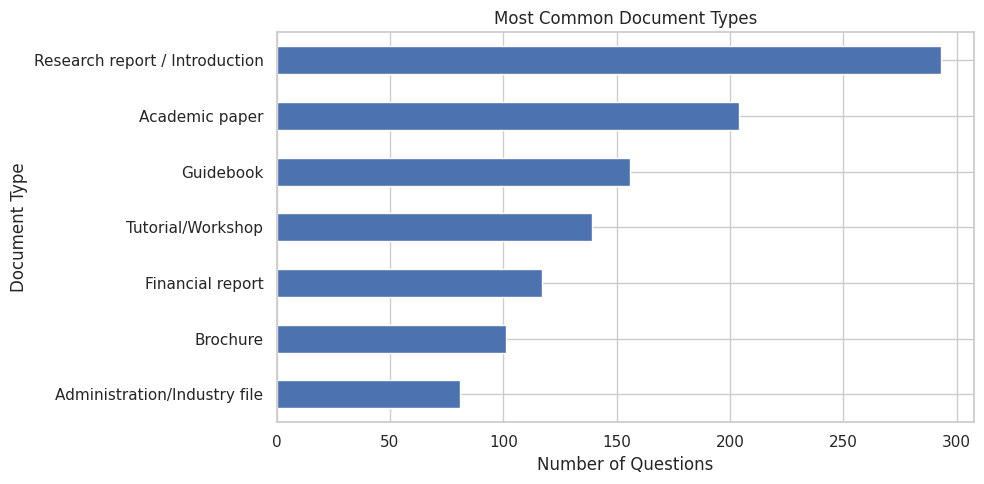

Answer formats:


,count
answer_format,
Int,290
Str,250
None,244
Float,160
List,147


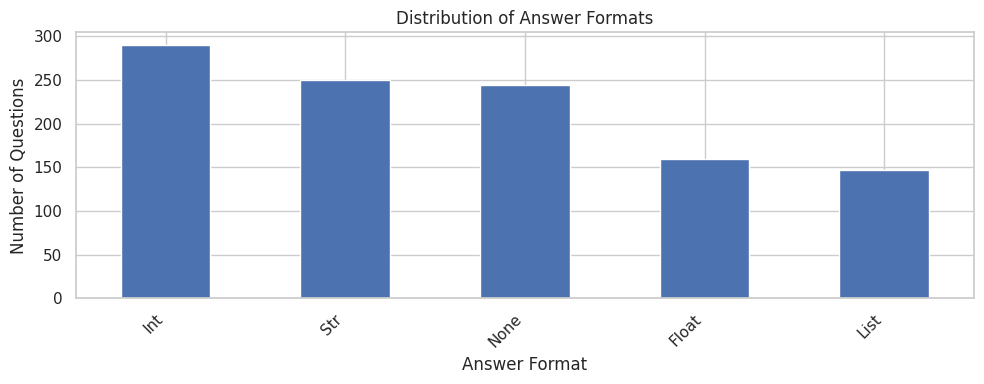

In [11]:
# Explore document types
if "doc_type" in df.columns:
    print("Document types:")
    display(df["doc_type"].value_counts(dropna=False).head(15))

    df["doc_type"].value_counts().head(15).sort_values().plot(
        kind="barh",
        figsize=(10, 5)
    )
    plt.title("Most Common Document Types")
    plt.xlabel("Number of Questions")
    plt.ylabel("Document Type")
    plt.tight_layout()
    plt.show()

# Explore answer formats
if "answer_format" in df.columns:
    print("Answer formats:")
    display(df["answer_format"].value_counts(dropna=False))

    df["answer_format"].value_counts().plot(
        kind="bar",
        figsize=(10, 4)
    )
    plt.title("Distribution of Answer Formats")
    plt.xlabel("Answer Format")
    plt.ylabel("Number of Questions")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Question length summary:


,characters
count,1091.000000
mean,95.215399
std,51.218299
min,12.000000
25%,59.500000
50%,82.000000
75%,114.000000
max,361.000000


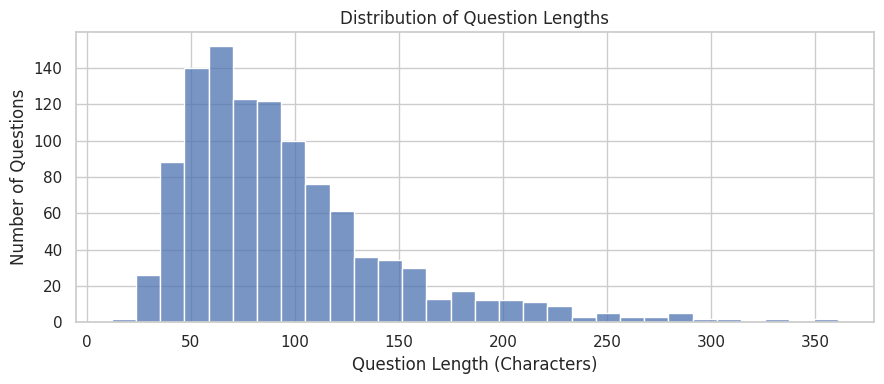

In [12]:
if "question" in df.columns:
    question_lengths = df["question"].fillna("").astype(str).str.len()

    print("Question length summary:")
    display(question_lengths.describe().to_frame("characters"))

    plt.figure(figsize=(9, 4))
    sns.histplot(question_lengths, bins=30)
    plt.title("Distribution of Question Lengths")
    plt.xlabel("Question Length (Characters)")
    plt.ylabel("Number of Questions")
    plt.tight_layout()
    plt.show()

In [15]:
duplicates_df = df[
    df.duplicated(
        subset=["doc_id", "question"],
        keep=False
    )
].sort_values(["doc_id", "question"])

display(duplicates_df)

,doc_id,doc_type,question,answer,evidence_pages,evidence_sources,answer_format
504,PRE_2022.09.29_NSL-politics_REPORT.pdf,Research report / Introduction,What proportion of the Spanish dominant Latino...,46%,[97],['Chart'],Float
505,PRE_2022.09.29_NSL-politics_REPORT.pdf,Research report / Introduction,What proportion of the Spanish dominant Latino...,Not answerable,[],[],None


In [17]:
%pip -q install huggingface_hub

from huggingface_hub import list_repo_files

repo_id = "yubo2333/MMLongBench-Doc"

files = list_repo_files(repo_id, repo_type="dataset")
pdf_files = [f for f in files if f.lower().endswith(".pdf")]

print("PDF files available:", len(pdf_files))
print("First 5 PDF paths:")
for file in pdf_files[:5]:
    print(file)

PDF files available: 135
First 5 PDF paths:
documents/05-03-18-political-release.pdf
documents/0b85477387a9d0cc33fca0f4becaa0e5.pdf
documents/0e94b4197b10096b1f4c699701570fbf.pdf
documents/11-21-16-Updated-Post-Election-Release.pdf
documents/12-15-15-ISIS-and-terrorism-release-final.pdf


In [18]:
from huggingface_hub import hf_hub_download

pdf_path = hf_hub_download(
    repo_id="yubo2333/MMLongBench-Doc",
    filename=pdf_files[0],
    repo_type="dataset"
)

print("PDF downloaded successfully:")
print(pdf_path)

documents/05-03-18-political-release.pdf: reconstructing file:   0%|          |  0.00B / 2.53MB            

documents/05-03-18-political-release.pdf: downloading bytes:           |  0.00B            

PDF downloaded successfully:
/root/.cache/huggingface/hub/datasets--yubo2333--MMLongBench-Doc/snapshots/2ff6aa9237fc777b6627dc57a486e9225ac5fb86/documents/05-03-18-political-release.pdf


In [19]:
from pathlib import Path

print("File exists:", Path(pdf_path).exists())
print("File name:", Path(pdf_path).name)

File exists: True
File name: 05-03-18-political-release.pdf


In [20]:
duplicates_df = df[
    df.duplicated(
        subset=["doc_id", "question"],
        keep=False
    )
].sort_values(["doc_id", "question"])

pd.set_option("display.max_colwidth", None)

display(
    duplicates_df[
        [
            "doc_id",
            "question",
            "answer",
            "evidence_pages",
            "evidence_sources",
            "answer_format"
        ]
    ]
)

,doc_id,question,answer,evidence_pages,evidence_sources,answer_format
504,PRE_2022.09.29_NSL-politics_REPORT.pdf,What proportion of the Spanish dominant Latinos express a negative impression of socialism?,46%,[97],['Chart'],Float
505,PRE_2022.09.29_NSL-politics_REPORT.pdf,What proportion of the Spanish dominant Latinos express a negative impression of socialism?,Not answerable,[],[],None


In [21]:
from huggingface_hub import hf_hub_download
from pathlib import Path

pdf_path = hf_hub_download(
    repo_id="yubo2333/MMLongBench-Doc",
    filename="documents/PRE_2022.09.29_NSL-politics_REPORT.pdf",
    repo_type="dataset"
)

print("PDF downloaded:", Path(pdf_path).exists())
print("PDF location:", pdf_path)

documents/PRE_2022.09.29_NSL-politics_RE(…): reconstructing file:   0%|          |  0.00B / 13.4MB            

documents/PRE_2022.09.29_NSL-politics_RE(…): downloading bytes:           |  0.00B            

PDF downloaded: True
PDF location: /root/.cache/huggingface/hub/datasets--yubo2333--MMLongBench-Doc/snapshots/2ff6aa9237fc777b6627dc57a486e9225ac5fb86/documents/PRE_2022.09.29_NSL-politics_REPORT.pdf


In [22]:
%pip -q install pymupdf

import fitz

doc = fitz.open(pdf_path)

print("Total PDF pages:", len(doc))

# PDF pages are indexed from 0, so index 96 is page 97.
page_index = 96

if page_index < len(doc):
    page = doc[page_index]
    print("\n--- PDF page 97 text ---\n")
    print(page.get_text()[:10000])
else:
    print("This PDF has fewer than 97 pages.")

Total PDF pages: 108

--- PDF page 97 text ---

 
 
Hispanic men (58%) are more 
likely than Hispanic women 
(50%) to say they have a 
negative impression of 
socialism.  
Roughly half of Latino 
immigrants (51%) say they 
have a negative impression of 
socialism. A similar share of 
U.S.-born Latinos (56%) say 
this.  
Latinos are divided by age on 
their impression of socialism, 
with roughly half of Latinos 
ages 18 to 29 (46%) reporting 
a positive impression of 
socialism, according to the 
Center’s survey. By contrast, 
majorities of Latinos ages 50 
to 64 (60%) and 65 and older 
(61%) say their impression of 
socialism is negative.  
Similar shares of Latinos 
(41%) and U.S. adults overall 
(36%) report positive 
impressions of socialism. 
However, U.S. adults overall 
(60%) are more likely than 
Latinos (54%) to express 
having a negative impression.  
 
 
Older Latinos more likely than younger Latinos to have 
a negative impression of socialism 
% of Latinos who say they have 

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


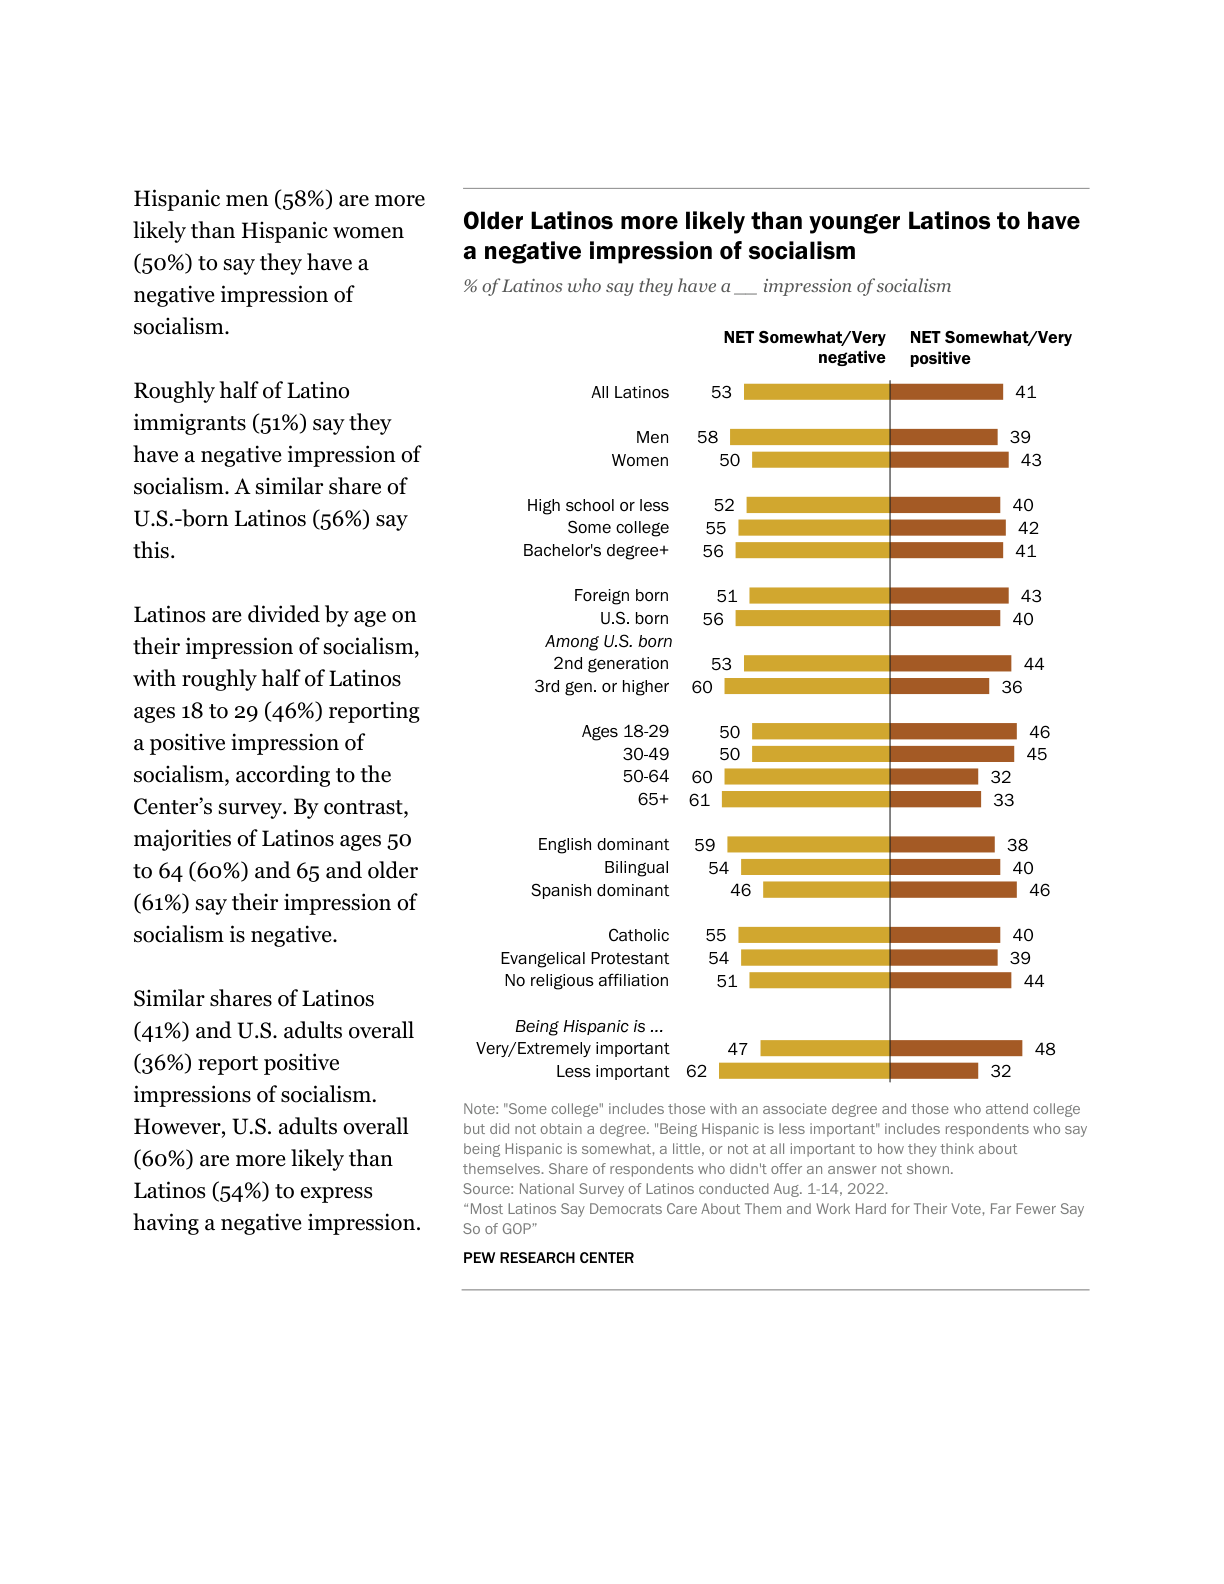

In [23]:
import pymupdf
from IPython.display import display, Image

doc = pymupdf.open(pdf_path)

page = doc[96]  # PDF page 97, zero-indexed
pix = page.get_pixmap(matrix=pymupdf.Matrix(2, 2))

display(Image(data=pix.tobytes("png")))

## Phase 2: Data Understanding — Initial Findings

### 2.1 Collect Initial Data
- Dataset Name: MMLongBench-Doc
- Dataset Source and URL: Hugging Face Datasets — https://huggingface.co/datasets/yubo2333/MMLongBench-Doc
- Date Accessed: October 25, 2026
- Loading Method: Loaded using the Hugging Face datasets library with load_dataset("yubo2333/MMLongBench-Doc")
- Loaded Split: Train
- Dataset Size: 1,091 question records
- Source Requirement Status: The dataset loaded successfully from Hugging Face. Its eligibility under the assignment's Kaggle or Papers with Code requirement still needs to be verified.

### 2.2 Describe Data
- Actual Number of Rows: 1,091
- Actual Number of Columns: 7
- Important Columns:
    - doc_id: Identifies the associated source document
    - doc_type: Describes the document category or section.
    - question: Contains the question to be answered using the document.
    - answer: Contains the reference answer or an unanswerable label.
    - evidence_pages: Identifies pages associated with supporting evidence.
    - evidence_sources: Identifies evidence types, such as charts or tables.
    - answer_format: Indicates the expected answer format, such as integer, string, float, list, or None.
- Data Types: All seven columns show up as object in pandas, but they hold different kinds of data. The object type doesn’t mean the values are all the same underneath.
- Availability of Accompanying PDFs: The question records point to PDF files, but it’s not confirmed that the PDFs actually exist or can be opened. This must be checked before testing document retrieval or answering questions based on them.

### 2.3 Explore Data
- Most Common Document Types: Research reports and introductions were the largest group with 293 questions, followed by academic papers, guidebooks, tutorials, financial reports, brochures, and industry files. Research reports made up about 26.9% of all records.
- Most Common Answer Formats: Int (290), Str (250), None (244), Float (160), and List (147). Integer answers were most common, and the meaning of None should be checked in the dataset documentation before assuming those records can’t be answered.
- Question-Length Observations: The average question length was about 95 characters (Standard 51). Lengths ranged from 12 characters to 361, with a median of 82. Most questions fall between 50–120 characters, with fewer very long ones.
- Other Notable Patterns: The duplicate pair has the same document ID and question but different answers and evidence: row 504 gives 46% with chart evidence, while row 505 says Not answerable with none. This mismatch needs review before using the pair in evaluation.

### 2.4 Verify Data Quality
- Missing Values: The missing-value check found zero missing values in each of the seven columns. Each column had a reported missing-value rate of 0%.
- Blank Questions or Answers: 0
- Duplicate Document-Question Pairs: The duplicate check identified one repeated document-question pair, represented by rows 504 and 505.
- Issues with Evidence Annotations: The duplicate pair shows different evidence: row 504 cites chart evidence from page 97, while row 505 has none.
- Limitations Discovered:
    - Eligibility under Kaggle or Papers with Code is still unverified.
    - Source PDF availability hasn’t been confirmed.
    - The duplicate document‑question pair has conflicting answers and evidence.
    - Reference answers and evidence haven’t been independently validated.
    - Dataset and source‑document licenses still need checking.
    - No missing fields doesn’t guarantee the records are accurate or reliable.

# 2.5 Duplicate Record Investigation

Two records (rows 504 and 505) share the same document ID and question but contain different answers. The question asks what proportion of Spanish-dominant Latinos express a negative impression of socialism.

Inspection of page 97 of the source PDF confirmed that the chart reports 46% for the net negative impression and 46% for the net positive impression among Spanish-dominant Latinos. Therefore, the answer `46%` in row 504 is supported by the source document. The `Not answerable` label in row 505 appears inconsistent with the available evidence.

**Decision:** Neither record was deleted or modified during initial data-quality inspection. The conflicting annotations will be documented as a potential data-quality issue and handled transparently during experimental preparation.

### 2.6 Dataset Source and Access

The dataset used in this project is MMLongBench-Doc: *Benchmarking Long-context Document Understanding with Visualizations*. The benchmark was developed to evaluate how effectively AI models understand long documents containing text, tables, charts, images, and other visual information.

The dataset was accessed through Hugging Face using the `datasets` Python library in Google Colab. The loaded version contains 1,091 question-and-answer records and references 135 PDF documents.

**Dataset and research resources:**

- **Hugging Face dataset:** https://huggingface.co/papers/2407.01523?utm_source=chatgpt.com$0
- **Official GitHub repository:** https://github.com/mayubo2333/MMLongBench-Doc?utm_source=chatgpt.com$0
- **Research paper on arXiv:** https://arxiv.org/abs/2407.01523?utm_source=chatgpt.com$0
- **Hugging Face paper page:** https://mayubo2333.github.io/MMLongBench-Doc/$0

The Hugging Face dataset loaded correctly, and the PDFs checked so far were accessible. A test PDF and the PDF for the duplicate‑record check both downloaded without issues.

However, the assignment requires choosing a dataset from Kaggle or Papers with Code, and MMLongBench‑Doc hasn’t been verified on either platform yet. This requirement must be confirmed before the dataset can be approved for the project.

### 2.7 Dataset License and Usage Restrictions

The MMLongBench‑Doc repository lists the dataset under a CC BY‑NC 4.0 license, which requires attribution and limits commercial use. Attribution to the original authors is required.

However, this license does not automatically cover every PDF in the dataset. Individual source documents may have their own copyright rules, so their permissions must be checked before any redistribution.

For this project, the dataset will only be used for school‑related analysis, and the PDFs won’t be shared unless their rules clearly allow it.

**License reference:** https://github.com/mayubo2333/MMLongBench-Doc

### 2.8 Limitations and Outstanding Issues

1. **Dataset-source requirement:** The dataset’s Kaggle or Papers with Code eligibility is still unverified.

2. **Potential annotation inconsistency:** Rows 504 and 505 share the same document ID and question but have different answers; the PDF supports 46%, not Not answerable.

3. **Source-document licensing:** Source‑PDF licensing may differ from the repository’s CC BY‑NC 4.0 license and must be checked.

4. **Answer and evidence verification:** Answers and evidence annotations haven’t been fully validated.

5. **Multimodal document complexity:** Some questions rely on charts, tables, images, or layout that text extraction may not capture.

6. **Model and evaluation limitations:** Retrieval, model accuracy, and evaluation quality haven’t been tested yet.

### Phase 2 Conclusion: Data Understanding

The dataset has 1,091 records across seven columns, with no missing questions, answers, or IDs. The analysis covered document types, answer formats, and question lengths. The linked PDFs were accessible, and one pair of records with the same document ID and question showed a possible inconsistency.
The dataset may be usable for document question‑answering, but key issues remain: its eligibility under the assignment’s Kaggle or Papers with Code requirement must be confirmed, and the licensing of the source PDFs needs to be checked before any redistribution.

**Phase 2 status:** Initial data understanding and preliminary quality checks are complete. Dataset approval and preparation for modeling remain conditional on resolving the outstanding source-requirement and data-quality issues.

## Phase 3: Data Preparation

In [24]:
df = samples.to_pandas().copy()

pilot_df = df.sample(
    n=min(30, len(df)),
    random_state=42
).reset_index(drop=True)

print("Pilot questions:", len(pilot_df))
display(pilot_df.head())

Pilot questions: 30


,doc_id,doc_type,question,answer,evidence_pages,evidence_sources,answer_format
0,dr-vorapptchapter1emissionsources-121120210508-phpapp02_95.pdf,Research report / Introduction,List all the PM health effects that increse by more than 35% in India and Thailand.,"['Cough', 'Phlegm', 'Adult Resp.']",[40],"['Pure-text (Plain-text)', 'Chart']",List
1,f86d073b0d735ac873a65d906ba82758.pdf,Financial report,WHAT IS ITC LIMITED LOGO COLOR?,Blue,[0],[],Str
2,BESTBUY_2023_10K.pdf,Financial report,"What is effective tax ratio of Best Buy for for the fiscal year ending January 28, 2023?Answer in percentage term, round to one decimal places.",20.7%,[40],['Table'],Float
3,2021-Apple-Catalog.pdf,Brochure,"Regarding macbook high security solution, which numbers of features are not presented in the illustration?",4,[22],"['Figure', 'Generalized-text (Layout)']",Int
4,2306.05425v1.pdf,Academic paper,How many line plots are shown in the slides?,Not answerable,[],[],None


In [25]:
pilot_df.to_csv(
    "crisp_dm_pilot_sample.csv",
    index=False
)

print("Pilot sample saved.")

Pilot sample saved.


In [26]:
from huggingface_hub import list_repo_files

repo_id = "yubo2333/MMLongBench-Doc"
repo_files = list_repo_files(repo_id, repo_type="dataset")

available_pdf_paths = {
    path.split("/")[-1]
    for path in repo_files
    if path.lower().endswith(".pdf")
}

pilot_df["pdf_available"] = pilot_df["doc_id"].isin(
    available_pdf_paths
)

print("Pilot questions:", len(pilot_df))
print("Matching PDFs:", pilot_df["pdf_available"].sum())
print("PDFs not matched:", (~pilot_df["pdf_available"]).sum())

display(
    pilot_df.loc[
        ~pilot_df["pdf_available"],
        ["doc_id", "question"]
    ]
)

Pilot questions: 30
Matching PDFs: 30
PDFs not matched: 0


,doc_id,question


## Phase 4: Modeling

In [27]:
print("Answer format counts in the pilot sample:")
display(pilot_df["answer_format"].value_counts())

print("\nPilot questions for review:")
display(
    pilot_df[
        [
            "doc_id",
            "doc_type",
            "question",
            "answer",
            "evidence_pages",
            "answer_format"
        ]
    ]
)

Answer format counts in the pilot sample:


,count
answer_format,
Int,8
None,7
List,6
Str,6
Float,3



Pilot questions for review:


,doc_id,doc_type,question,answer,evidence_pages,answer_format
0,dr-vorapptchapter1emissionsources-121120210508-phpapp02_95.pdf,Research report / Introduction,List all the PM health effects that increse by more than 35% in India and Thailand.,"['Cough', 'Phlegm', 'Adult Resp.']",[40],List
1,f86d073b0d735ac873a65d906ba82758.pdf,Financial report,WHAT IS ITC LIMITED LOGO COLOR?,Blue,[0],Str
2,BESTBUY_2023_10K.pdf,Financial report,"What is effective tax ratio of Best Buy for for the fiscal year ending January 28, 2023?Answer in percentage term, round to one decimal places.",20.7%,[40],Float
3,2021-Apple-Catalog.pdf,Brochure,"Regarding macbook high security solution, which numbers of features are not presented in the illustration?",4,[22],Int
4,2306.05425v1.pdf,Academic paper,How many line plots are shown in the slides?,Not answerable,[],None
5,2303.05039v2.pdf,Academic paper,How many items in total of Shopee related datasets in the paper? Please write the answer in int format.,Not answerable,[],None
6,e79deb02a0c0e87511080836c5d4347b.pdf,Administration/Industry file,How many appendices appear in the document?,5,"[7, 11, 13, 16, 17]",Int
7,2303.08559v2.pdf,Academic paper,"If I drop the green module shown in Figure 6, what is the absolute percentage drop on 100-shot TACREV setting?",0.5%,"[8, 9]",Float
8,2303.05039v2.pdf,Academic paper,How many items in total of Amazon related datasets in the paper? Please write the answer in int format.,8980,[4],Int
9,2312.09390v1.pdf,Academic paper,List all the sections that discuss about the experiment setup?,"['Section 4.1', 'Section 4.2', 'Section 4.3', 'Appendix A']","[7, 8, 9, 10, 28]",List


In [28]:
from google.colab import files
files.download("crisp_dm_pilot_sample.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
selected_indices = [1, 2, 4, 23, 19]

test_df = pilot_df.loc[selected_indices].copy()

display(
    test_df[
        [
            "doc_id",
            "doc_type",
            "question",
            "answer",
            "evidence_pages",
            "answer_format"
        ]
    ]
)

,doc_id,doc_type,question,answer,evidence_pages,answer_format
1,f86d073b0d735ac873a65d906ba82758.pdf,Financial report,WHAT IS ITC LIMITED LOGO COLOR?,Blue,[0],Str
2,BESTBUY_2023_10K.pdf,Financial report,"What is effective tax ratio of Best Buy for for the fiscal year ending January 28, 2023?Answer in percentage term, round to one decimal places.",20.7%,[40],Float
4,2306.05425v1.pdf,Academic paper,How many line plots are shown in the slides?,Not answerable,[],None
23,05-03-18-political-release.pdf,Research report / Introduction,"What percentage of the party that holds the highest total percentage of good policy ideas and high ethical standards reported that they followed the news about congressional elections in their state very closely in the survey of U.S. adults conducted from April 25 to May 1, 2018?",21%,"[11, 13]",Int
19,91521110100M_4K_UHD_Display_User_Manual_V1.1.pdf,Guidebook,"For the users with the safety approval of UL Listed and CSA , what is the second bullet point for safety?",Operate the unit on 100-240V AC only.,[25],Str


In [30]:
from pathlib import Path
from huggingface_hub import hf_hub_download

pdf_folder = Path("/content/crisp_dm_test_pdfs")
pdf_folder.mkdir(parents=True, exist_ok=True)

for _, row in test_df.iterrows():
    filename = f"documents/{row['doc_id']}"

    downloaded_path = hf_hub_download(
        repo_id="yubo2333/MMLongBench-Doc",
        filename=filename,
        repo_type="dataset",
        local_dir=str(pdf_folder)
    )

    print("Downloaded:", row["doc_id"])

f86d073b0d735ac873a65d906ba82758.pdf:   0%|          | 0.00/273k [00:00<?, ?B/s]

Downloaded: f86d073b0d735ac873a65d906ba82758.pdf


BESTBUY_2023_10K.pdf:   0%|          | 0.00/703k [00:00<?, ?B/s]

Downloaded: BESTBUY_2023_10K.pdf


documents/2306.05425v1.pdf: reconstructing file:   0%|          |  0.00B / 9.81MB            

documents/2306.05425v1.pdf: downloading bytes:           |  0.00B            

Downloaded: 2306.05425v1.pdf
Downloaded: 05-03-18-political-release.pdf


documents/91521110100M_4K_UHD_Display_Us(…): reconstructing file:   0%|          |  0.00B / 1.68MB            

documents/91521110100M_4K_UHD_Display_Us(…): downloading bytes:           |  0.00B            

Downloaded: 91521110100M_4K_UHD_Display_User_Manual_V1.1.pdf


In [31]:
downloaded_pdfs = list(pdf_folder.rglob("*.pdf"))

print("Expected PDFs:", len(test_df))
print("Downloaded PDFs:", len(downloaded_pdfs))

for path in downloaded_pdfs:
    print(path.name, "-", round(path.stat().st_size / (1024 * 1024), 2), "MB")

Expected PDFs: 5
Downloaded PDFs: 5
91521110100M_4K_UHD_Display_User_Manual_V1.1.pdf - 1.6 MB
2306.05425v1.pdf - 9.35 MB
f86d073b0d735ac873a65d906ba82758.pdf - 0.26 MB
BESTBUY_2023_10K.pdf - 0.67 MB
05-03-18-political-release.pdf - 2.41 MB


In [32]:
%pip -q install pymupdf

import pymupdf

for pdf_path in downloaded_pdfs:
    doc = pymupdf.open(pdf_path)
    first_page_text = doc[0].get_text().strip()

    print("\n" + "=" * 70)
    print("PDF:", pdf_path.name)
    print("Total pages:", len(doc))
    print("Text extracted from first page:", len(first_page_text), "characters")
    print(first_page_text[:500] if first_page_text else "No text extracted from first page.")
    doc.close()


PDF: 91521110100M_4K_UHD_Display_User_Manual_V1.1.pdf
Total pages: 40
Text extracted from first page: 218 characters
User Manual 
M270TF-XXX 
M320TF-XXX 
LCD Monitor 
 
 
 
Document Part No. 91521110100M 
Document Version V1.1 
 
 
 
 
 
Before operating the unit, please read this manual thoroughly and retain it for future reference.

PDF: 2306.05425v1.pdf
Total pages: 22
Text extracted from first page: 3242 characters
MIMIC-IT: Multi-Modal In-Context
Instruction Tuning
Bo Li∗,♠,1 Yuanhan Zhang∗,♠,1 Liangyu Chen∗,1 Jinghao Wang∗,1 Fanyi Pu∗,1
Jingkang Yang1
Chunyuan Li2
Ziwei Liu1,B
1S-Lab, Nanyang Technological University, Singapore
2Microsoft Research, Redmond
{libo0013, yuanhan002, lchen025, c190209, fpu001, ziwei.liu}@ntu.edu.sg
chunyl@microsoft.com
https://github.com/Luodian/Otter
Abstract
High-quality instructions and responses are essential for the zero-shot performance
of large language models on inter

PDF: f86d073b0d735ac873a65d906ba82758.pdf
Total pages: 20
Text extracted f

## 3.1 Pilot Document Availability and Readability
A pilot test set of five questions was selected from the 30-question sample using a reproducible selection process. The five corresponding PDF documents were downloaded successfully from the MMLongBench-Doc dataset repository.

The documents were inspected using PyMuPDF to determine their page counts and whether text could be extracted from their first pages.

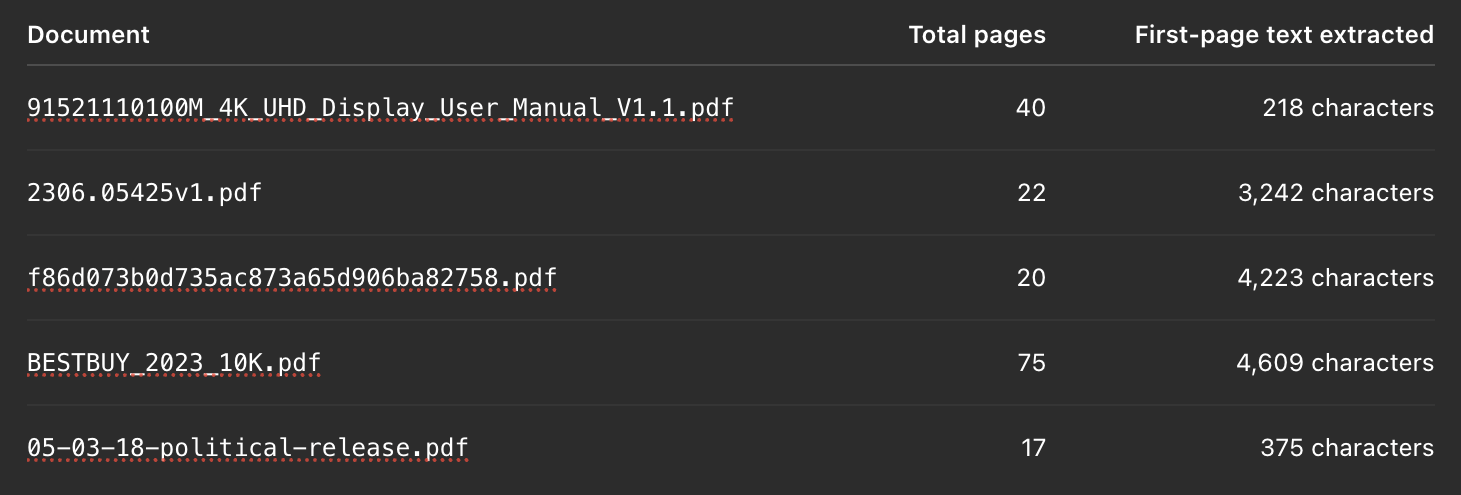

Text was extracted from the first page of all five documents. The extracted previews included recognizable document content, such as a monitor user manual, an academic paper, a corporate governance report, a financial annual report, and a Pew Research Center publication.

Preparation outcome: All five documents were successfully downloaded and passed the initial first-page text-extraction check. This confirms basic document readability, but it does not establish that every relevant page, chart, table, or figure can be interpreted correctly. Further checks are needed during modeling and evaluation.

In [33]:
import pymupdf

for _, row in test_df.iterrows():
    matching_files = [
        path for path in downloaded_pdfs
        if path.name == row["doc_id"]
    ]

    if not matching_files:
        print("PDF not found:", row["doc_id"])
        continue

    doc = pymupdf.open(matching_files[0])

    print("\n" + "=" * 80)
    print("QUESTION:", row["question"])
    print("REFERENCE ANSWER:", row["answer"])
    print("EVIDENCE PAGES:", row["evidence_pages"])

    page_numbers = row["evidence_pages"]

    if isinstance(page_numbers, list) and page_numbers:
        for page_number in page_numbers:
            # Dataset page numbers may not match zero-based PDF indices.
            for index in {max(0, int(page_number) - 1),
                          min(len(doc) - 1, int(page_number))}:
                print(f"\n--- PDF page index {index} ---")
                print(doc[index].get_text()[:2000])
    else:
        print("No evidence pages listed; inspect the document for the question.")

    doc.close()


QUESTION: WHAT IS ITC LIMITED LOGO COLOR?
REFERENCE ANSWER: Blue
EVIDENCE PAGES: [0]
No evidence pages listed; inspect the document for the question.

QUESTION: What is effective tax ratio of Best Buy for for the fiscal year ending January 28, 2023?Answer in percentage term, round to one decimal places.
REFERENCE ANSWER: 20.7%
EVIDENCE PAGES: [40]
No evidence pages listed; inspect the document for the question.

QUESTION: How many line plots are shown in the slides?
REFERENCE ANSWER: Not answerable
EVIDENCE PAGES: []
No evidence pages listed; inspect the document for the question.

QUESTION: What percentage of the party that holds the highest total percentage of good policy ideas and high ethical standards reported that they followed the news about congressional elections in their state very closely in the survey of U.S. adults conducted from April 25 to May 1, 2018?
REFERENCE ANSWER: 21%
EVIDENCE PAGES: [11, 13]
No evidence pages listed; inspect the document for the question.

QUESTI

In [35]:
import ast
import pymupdf

for _, row in test_df.iterrows():
    matching_files = [
        path for path in downloaded_pdfs
        if path.name == row["doc_id"]
    ]

    print("\n" + "=" * 80)
    print("QUESTION:", row["question"])
    print("REFERENCE ANSWER:", row["answer"])

    if not matching_files:
        print("PDF not found:", row["doc_id"])
        continue

    # Convert the string '[40]' into the Python list [40].
    evidence_value = row["evidence_pages"]

    if isinstance(evidence_value, str):
        evidence_pages = ast.literal_eval(evidence_value)
    else:
        evidence_pages = evidence_value

    print("Evidence pages:", evidence_pages)

    doc = pymupdf.open(matching_files[0])

    if evidence_pages:
        for page_number in evidence_pages:
            page_number = int(page_number)

            # Check both common interpretations of page numbering.
            page_indices = {
                page_number - 1,
                page_number
            }

            for index in sorted(page_indices):
                if 0 <= index < len(doc):
                    print(f"\n--- PDF page index {index} ---")
                    text = doc[index].get_text().strip()
                    print(text[:2500] if text else
                          "No selectable text on this page.")
    else:
        print("No evidence pages listed for this question.")

    doc.close()


QUESTION: WHAT IS ITC LIMITED LOGO COLOR?
REFERENCE ANSWER: Blue
Evidence pages: [0]

--- PDF page index 0 ---
The Directors present the Company’s Report on
Corporate Governance.
ITC Limited has been one of the frontrunners in
India to have put in place a formalised system of
Corporate Governance.
THE COMPANY’S GOVERNANCE
PHILOSOPHY
ITC defines Corporate Governance as a systemic
process by which companies are directed and
controlled to enhance their wealth-generating
capacity. Since large corporations employ a vast
quantum of societal resources, ITC believes that
the governance process should ensure that these
resources are utilised in a manner that meets
stakeholders’ aspirations and societal expectations.
This belief is reflected in the Company’s deep
commitment to contribute to the “triple bottom
line”, namely the development, nurture and
regeneration of the nation’s economic, social and
environmental capital.
ITC's Corporate Governance structure, systems
and processes are based on

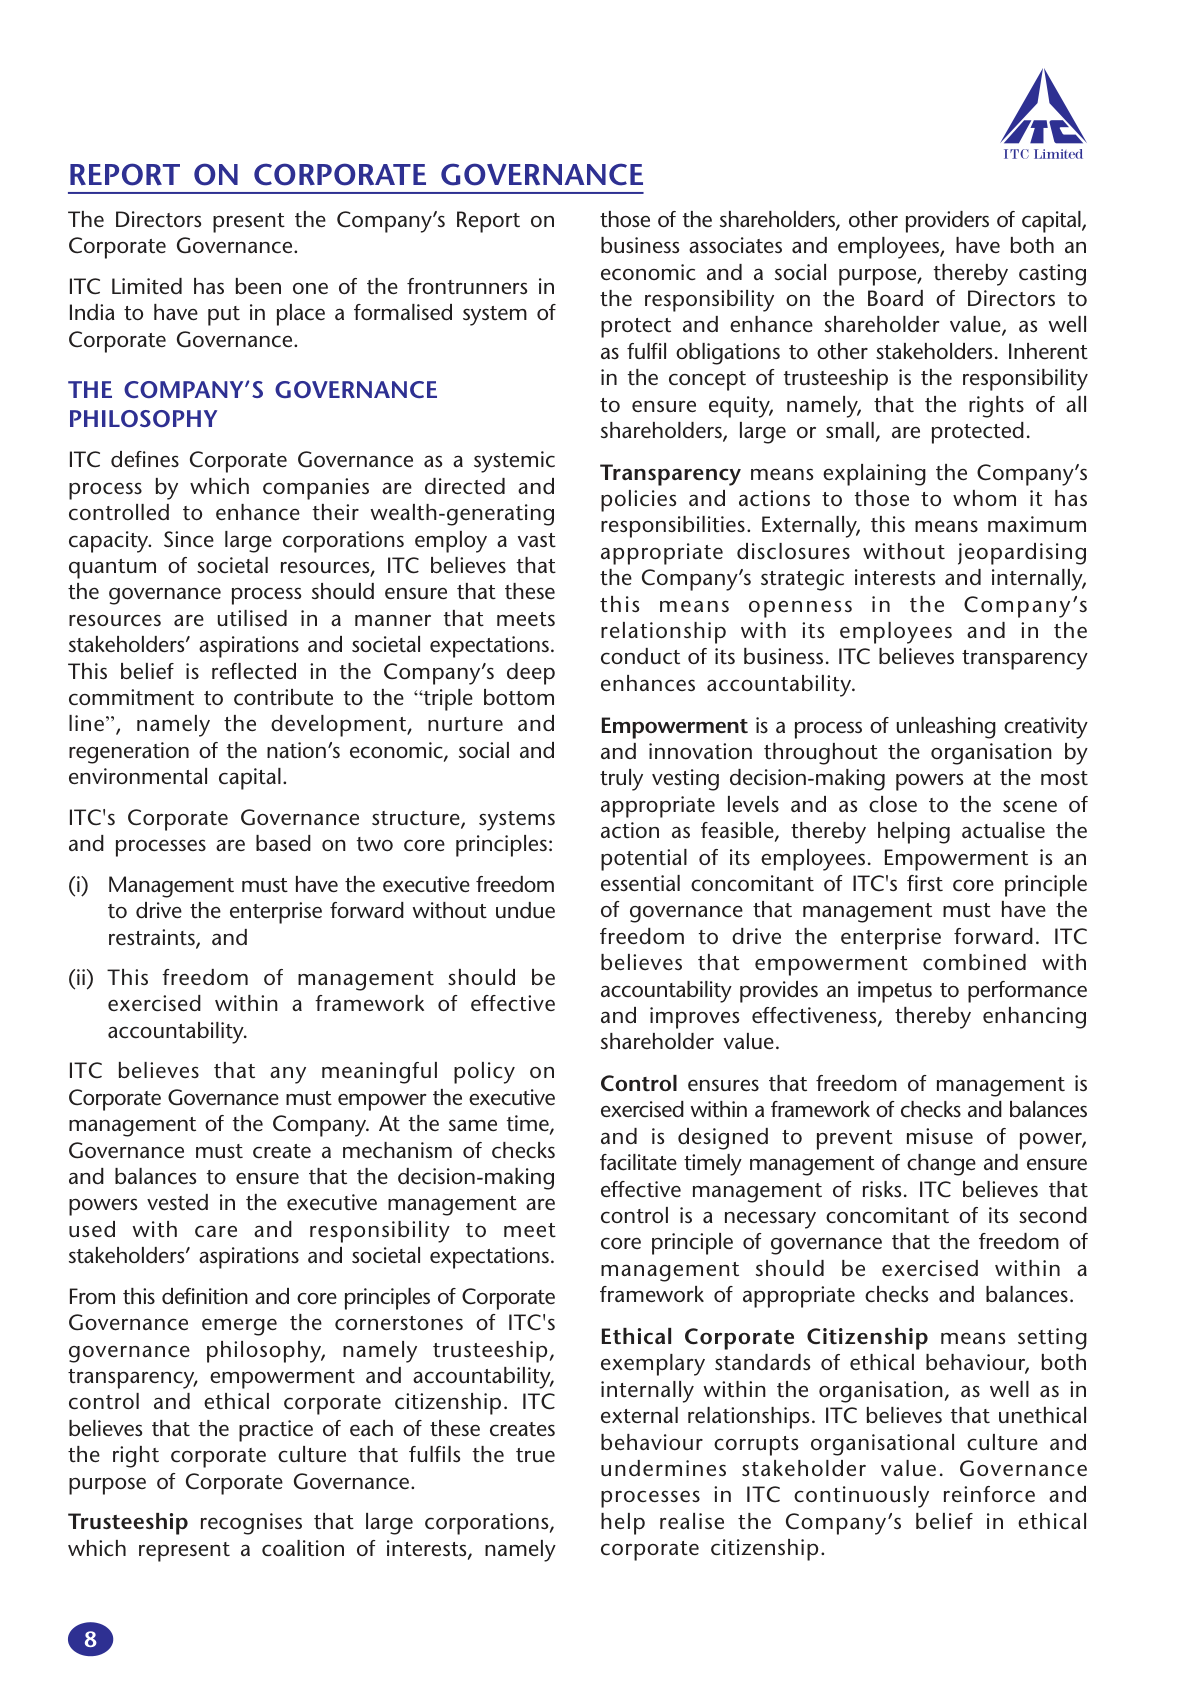

In [36]:
import pymupdf
from IPython.display import display, Image

itc_path = next(
    p for p in downloaded_pdfs
    if p.name == "f86d073b0d735ac873a65d906ba82758.pdf"
)

doc = pymupdf.open(itc_path)
page = doc[0]
pix = page.get_pixmap(matrix=pymupdf.Matrix(2, 2))

display(Image(data=pix.tobytes("png")))
doc.close()

In [37]:
import pymupdf

# Find the MIMIC-IT PDF in your downloaded test documents.
mimic_path = next(
    p for p in downloaded_pdfs
    if p.name == "2306.05425v1.pdf"
)

doc = pymupdf.open(mimic_path)

print("Document pages:", len(doc))

for i, page in enumerate(doc):
    text = page.get_text()
    terms = ["line plot", "line plots", "slides", "plot"]
    matches = [
        term for term in terms
        if term.lower() in text.lower()
    ]

    if matches:
        print(f"\nPDF page {i + 1} — matches: {matches}")
        print(text[:1800])

doc.close()

Document pages: 22

PDF page 7 — matches: ['plot']
identify
suggest
see
take
describe
provide
have
do
face
use
give
observe
pick
play
recommend
notice
affect
explain
put
find
object
item
type
hazard
way
option
recipe
item
object
item
sign
tool
action
precaution
place
picture
surrounding
appearance
atmosphere
object
information
detail
insight
tip
conversation
impact
trouble
kind
character
activity
kind
person
challenge
risk
difficulty
issue
tool
type
equipment
phone
advice
instruction
information
overview
person
object
item
user
item
kind
object
type
role
game
book
way
option
item
person
object
item
bottle
performance
experience
atmosphere
difference
role
importance
significance
item
book
book
provide
see
determine
have
wear
take
play
observe
hold
feature
identify
use
show
depict
capture
notice
pick
place
put
include
information
view
detail
answer
object
person
item
book
type
location
content
purpose
information
conversation
impact
benefit
shirt
gear
glove
jacket
place
precaution
pictur

In [38]:
pew_path = next(
    p for p in downloaded_pdfs
    if p.name == "05-03-18-political-release.pdf"
)

doc = pymupdf.open(pew_path)

for page_index in [8, 9, 10, 11, 12, 13]:
    if page_index < len(doc):
        print("\n" + "=" * 70)
        print(f"PDF page {page_index + 1}")
        print(doc[page_index].get_text()[:4000])

doc.close()


PDF page 9
7 
PEW RESEARCH CENTER 
www.pewresearch.org 
Poor
Not good
Good
Excellent
36 
7 
5 
12 
61 
52 
73 
38 
59 
10 
9 
19 
22 
12 
2 
3 
7 
3 
15 
Total
Rep/Lean Rep
Conserv
Mod/Lib
Dem/Lean Dem
Cons/Mod
Liberal
All
Lean Dem
Lean Rep
88 
65 
86 
36 
15 
22 
58 
39 
75 
82
61 
12 
31 
31 
Lean Rep 
Lean Dem 
19 
80 
93 
5 
10 
67 
Among independents* 
Conserv 
Mod/Lib 
Cons/Mod 
Liberal 
Today, three-quarters of Republicans (75%) rate the ethical standards of key administration 
members as good or excellent, while 86% of Democrats say they are not good or poor – including 
61% who rate them as poor.  
Among Republicans and Republican leaners, 
these views diverge significantly by ideology.  
While just 15% of conservative Republicans 
express negative views of the ethical standards 
of Trump administration officials, about a 
third (36%) of moderate and liberal 
Republicans say they are not good or poor. 
Among Democrats, there are also modest 
differences along ideological line

PDF page index 10 (printed page 8)


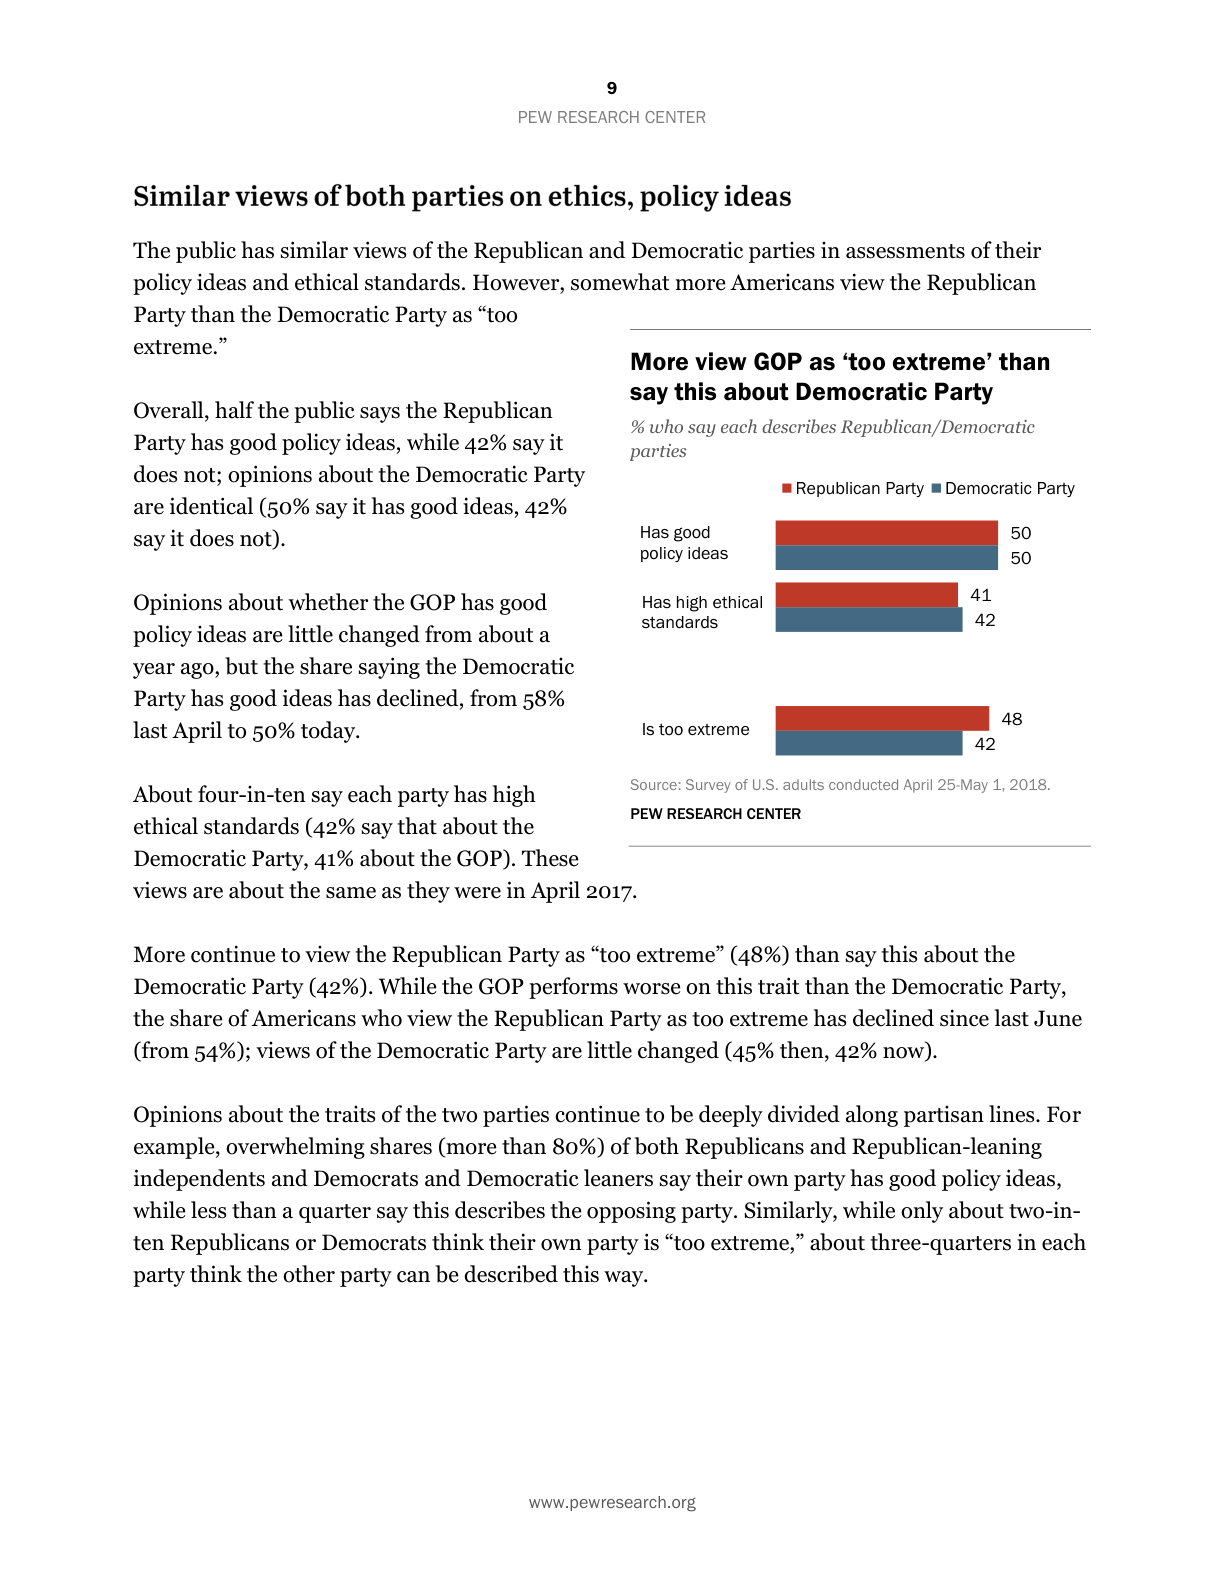

PDF page index 12 (printed page 10)


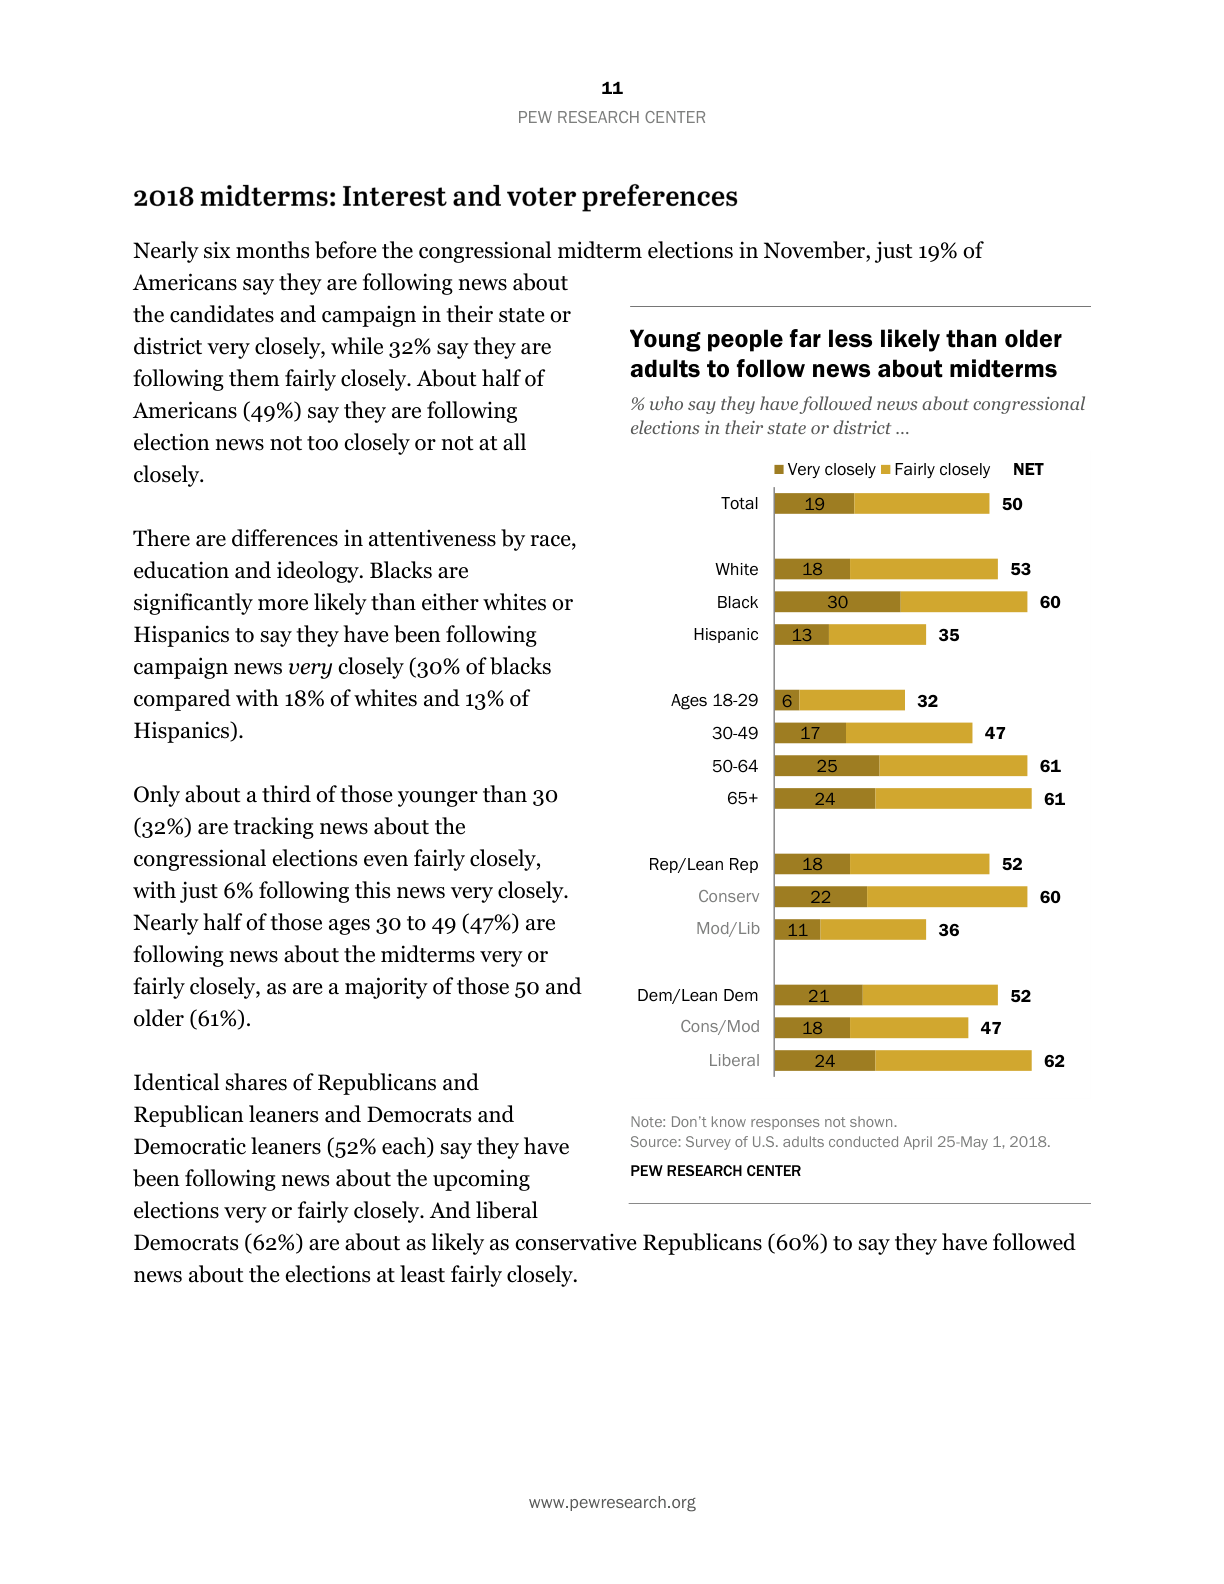

In [39]:
import pymupdf
from IPython.display import display, Image

pew_path = next(
    p for p in downloaded_pdfs
    if p.name == "05-03-18-political-release.pdf"
)

doc = pymupdf.open(pew_path)

# PDF page indices 10 and 12 correspond to printed pages 8 and 10.
for page_index in [10, 12]:
    page = doc[page_index]
    pix = page.get_pixmap(matrix=pymupdf.Matrix(2, 2))

    print(f"PDF page index {page_index} (printed page {page_index - 2})")
    display(Image(data=pix.tobytes("png")))

doc.close()

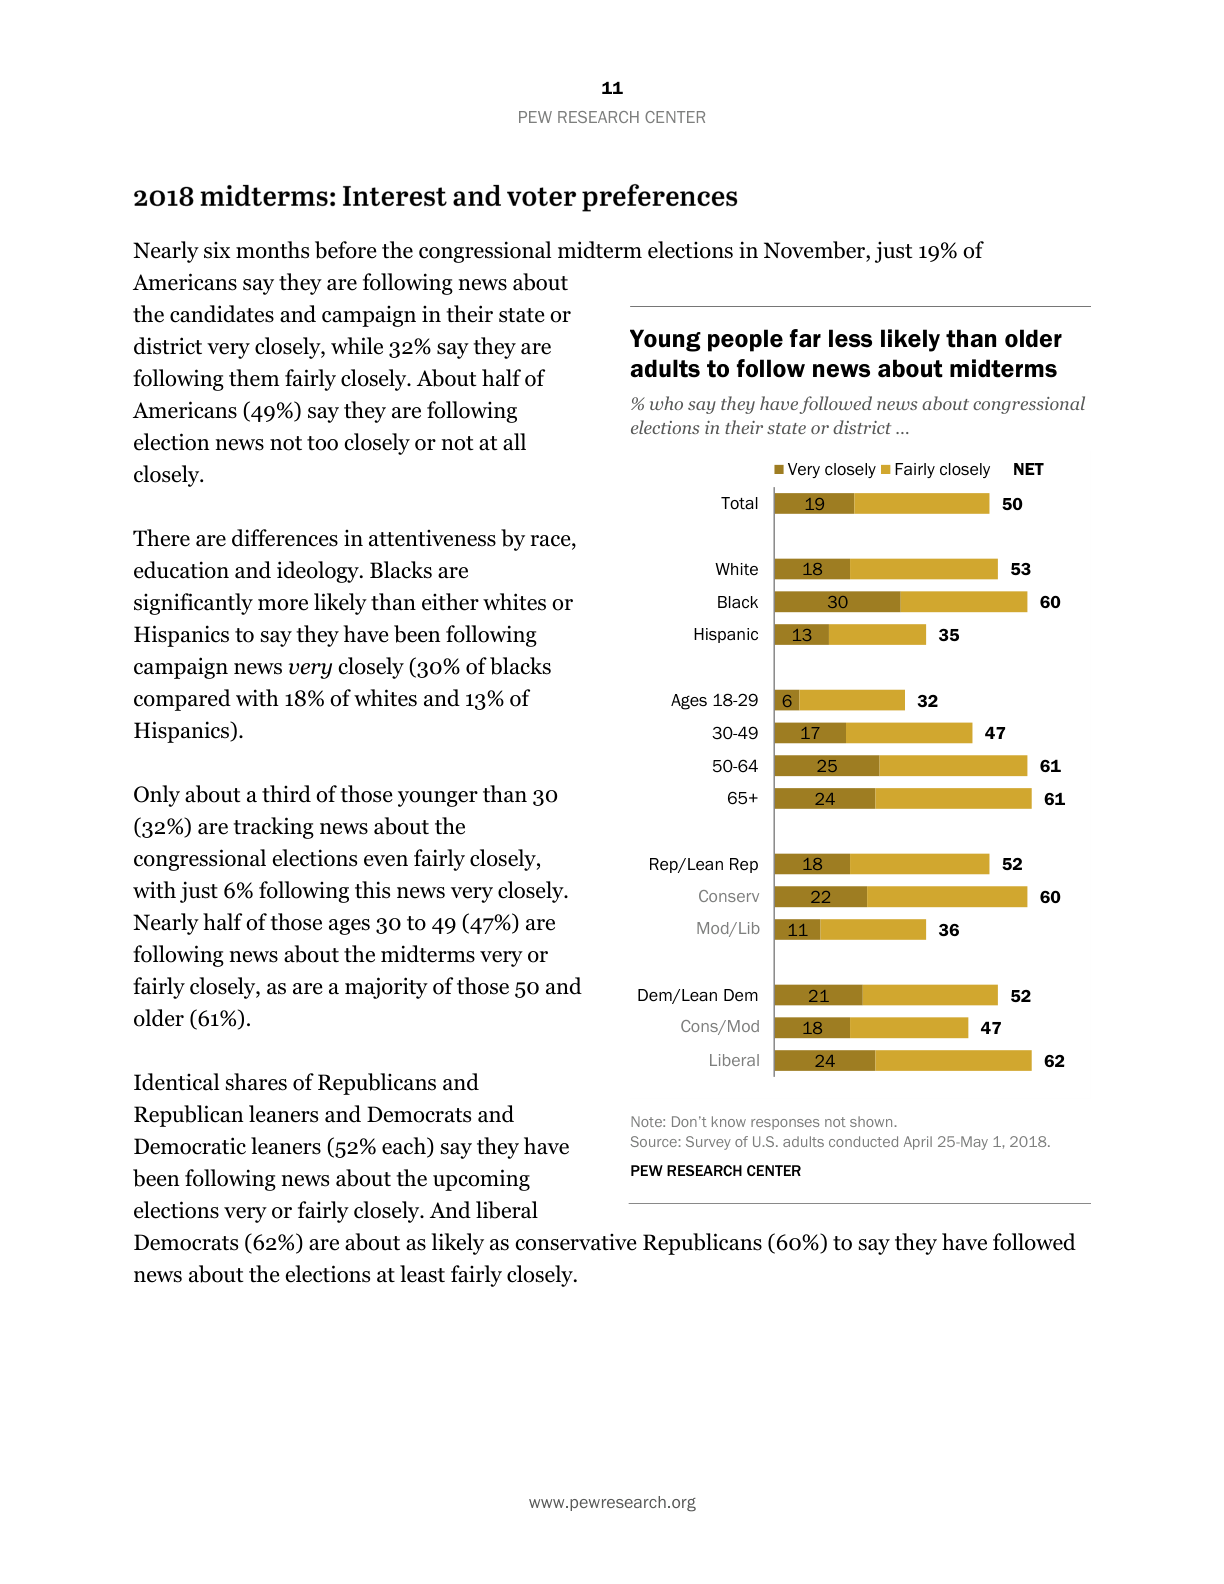

In [40]:
import pymupdf
from IPython.display import display, Image

pew_path = next(
    p for p in downloaded_pdfs
    if p.name == "05-03-18-political-release.pdf"
)

doc = pymupdf.open(pew_path)

# Printed page 11; PDF index 12.
page = doc[12]
pix = page.get_pixmap(matrix=pymupdf.Matrix(2, 2))
display(Image(data=pix.tobytes("png")))

doc.close()

## 3.2 Pilot Reference-Answer Verification

A five‑question sample was checked against its PDFs to see if the answers were correct.
- ITC logo: The PDF shows the logo is blue, matching the answer.
- Best Buy tax ratio: The numbers in the report give about 20.7%, matching the answer.
- MIMIC‑IT plot: Labeled Not answerable; the PDF has figures, but it’s still unclear whether the needed plot exists.
- Pew election‑news question: The chart shows 21% for Democrats, but the question wording is unclear. The answer is possible but needs caution.
- Monitor safety instruction: The manual supports “Operate on 100–240V AC only.”

Three answers are confirmed, one is partly supported, and one remains unresolved. These results will be kept as‑is for transparent evaluation.

## Phase 4: Modeling

In [41]:
%pip install -q raganything

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 1.75.0 which is incompatible.


In [42]:
import raganything

print("RAG-Anything imported successfully.")
print("Package location:", raganything.__file__)

RAG-Anything imported successfully.
Package location: /usr/local/lib/python3.13/dist-packages/raganything/__init__.py


In [43]:
from importlib.metadata import version, PackageNotFoundError

for package in ["raganything", "lightrag-hku", "mineru", "google-genai"]:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")

raganything: 1.4.3
lightrag-hku: 1.4.16
mineru: 4.0.12
google-genai: 1.75.0


In [45]:
from pathlib import Path

# Check the expected folder.
pdf_folder = Path("/content/crisp_dm_test_pdfs")

print("Expected folder exists:", pdf_folder.exists())

if pdf_folder.exists():
    print("Files in expected folder:")
    for path in pdf_folder.iterdir():
        print(path.name)

# Search /content for PDFs in other folders.
print("\nPDF files found anywhere under /content:")

all_pdfs = list(Path("/content").rglob("*.pdf"))

for path in all_pdfs:
    print(path)

print("\nTotal PDFs found:", len(all_pdfs))

Expected folder exists: True
Files in expected folder:
documents
.cache

PDF files found anywhere under /content:
/content/crisp_dm_test_pdfs/documents/91521110100M_4K_UHD_Display_User_Manual_V1.1.pdf
/content/crisp_dm_test_pdfs/documents/2306.05425v1.pdf
/content/crisp_dm_test_pdfs/documents/f86d073b0d735ac873a65d906ba82758.pdf
/content/crisp_dm_test_pdfs/documents/BESTBUY_2023_10K.pdf
/content/crisp_dm_test_pdfs/documents/05-03-18-political-release.pdf

Total PDFs found: 5


In [46]:
# Building The Local Retrieval
import ast
from pathlib import Path

import pymupdf
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Locate the five PDFs downloaded earlier.
pdf_folder = Path("/content/crisp_dm_test_pdfs/documents")
pdf_files = sorted(pdf_folder.glob("*.pdf"))

print("PDF files found:", len(pdf_files))
for path in pdf_files:
    print(path.name)

assert len(pdf_files) == 5, "Expected to find all five PDFs."

# Extract selectable text from each PDF, one page at a time.
pages = []

for pdf_path in pdf_files:
    with pymupdf.open(pdf_path) as doc:
        for page_index, page in enumerate(doc):
            text = page.get_text().strip()

            if text:
                pages.append({
                    "doc_id": pdf_path.name,
                    "page_index": page_index,  # Zero-based
                    "page_number": page_index + 1,  # Human-readable
                    "text": text
                })

pages_df = pd.DataFrame(pages)

print("Pages with selectable text:", len(pages_df))
display(pages_df[["doc_id", "page_number"]].head(10))

# Build the TF-IDF search index.
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=50000
)

page_vectors = vectorizer.fit_transform(pages_df["text"])

print("TF-IDF index built successfully.")
print("Pages indexed:", page_vectors.shape[0])
print("Vocabulary size:", page_vectors.shape[1])

PDF files found: 5
05-03-18-political-release.pdf
2306.05425v1.pdf
91521110100M_4K_UHD_Display_User_Manual_V1.1.pdf
BESTBUY_2023_10K.pdf
f86d073b0d735ac873a65d906ba82758.pdf
Pages with selectable text: 174


,doc_id,page_number
0,05-03-18-political-release.pdf,1
1,05-03-18-political-release.pdf,2
2,05-03-18-political-release.pdf,3
3,05-03-18-political-release.pdf,4
4,05-03-18-political-release.pdf,5
5,05-03-18-political-release.pdf,6
6,05-03-18-political-release.pdf,7
7,05-03-18-political-release.pdf,8
8,05-03-18-political-release.pdf,9
9,05-03-18-political-release.pdf,10


TF-IDF index built successfully.
Pages indexed: 174
Vocabulary size: 42221


In [47]:
# Retrieving The Top 3 Pages For Each Question
import ast
from sklearn.metrics.pairwise import cosine_similarity

results = []

for _, question_row in test_df.iterrows():
    question = str(question_row["question"])
    expected_doc = str(question_row["doc_id"])

    # Transform the question using the existing TF-IDF index.
    question_vector = vectorizer.transform([question])
    scores = cosine_similarity(
        question_vector, page_vectors
    ).ravel()

    # Rank pages from highest to lowest similarity.
    top_indices = scores.argsort()[::-1][:3]

    # Read the dataset's evidence-page annotation.
    raw_evidence = question_row["evidence_pages"]

    if isinstance(raw_evidence, str):
        evidence_pages = ast.literal_eval(raw_evidence)
    else:
        evidence_pages = raw_evidence

    evidence_pages = [int(p) for p in evidence_pages]

    # A match is only meaningful when evidence pages are provided.
    exact_hit = False
    adjacent_hit = False

    print("\n" + "=" * 90)
    print("QUESTION:", question)
    print("REFERENCE ANSWER:", question_row["answer"])
    print("EXPECTED DOCUMENT:", expected_doc)
    print("ANNOTATED EVIDENCE PAGES:", evidence_pages)

    for rank, page_idx in enumerate(top_indices, start=1):
        page = pages_df.iloc[page_idx]

        is_expected_doc = page["doc_id"] == expected_doc

        # Check both common page-index conventions.
        exact_match = (
            is_expected_doc
            and page["page_index"] in evidence_pages
        )

        adjacent_match = (
            is_expected_doc
            and any(
                abs(page["page_index"] - p) <= 1
                for p in evidence_pages
            )
        )

        exact_hit = exact_hit or exact_match
        adjacent_hit = adjacent_hit or adjacent_match

        print(f"\nRank: {rank}")
        print(f"Document: {page['doc_id']}")
        print(f"PDF page: {page['page_number']}")
        print(f"TF-IDF similarity: {scores[page_idx]:.4f}")
        print("Matches expected document:", is_expected_doc)
        print("Text excerpt:")
        print(page["text"][:700].replace("\n", " "))

    if evidence_pages:
        print("\nExact evidence-page hit in top 3:", exact_hit)
        print("Evidence page within ±1 page in top 3:", adjacent_hit)
    else:
        print("\nEvidence-page hit: Not evaluable (no evidence pages annotated)")

    results.append({
        "question": question,
        "expected_document": expected_doc,
        "evidence_pages": evidence_pages,
        "exact_evidence_hit_at_3": exact_hit if evidence_pages else None,
        "adjacent_evidence_hit_at_3": adjacent_hit if evidence_pages else None
    })

retrieval_results_df = pd.DataFrame(results)

print("\nSUMMARY")
display(retrieval_results_df)


QUESTION: WHAT IS ITC LIMITED LOGO COLOR?
REFERENCE ANSWER: Blue
EXPECTED DOCUMENT: f86d073b0d735ac873a65d906ba82758.pdf
ANNOTATED EVIDENCE PAGES: [0]

Rank: 1
Document: f86d073b0d735ac873a65d906ba82758.pdf
PDF page: 1
TF-IDF similarity: 0.1185
Matches expected document: True
Text excerpt:
The Directors present the Company’s Report on Corporate Governance. ITC Limited has been one of the frontrunners in India to have put in place a formalised system of Corporate Governance. THE COMPANY’S GOVERNANCE PHILOSOPHY ITC defines Corporate Governance as a systemic process by which companies are directed and controlled to enhance their wealth-generating capacity. Since large corporations employ a vast quantum of societal resources, ITC believes that the governance process should ensure that these resources are utilised in a manner that meets stakeholders’ aspirations and societal expectations. This belief is reflected in the Company’s deep commitment to contribute to the “triple bottom 

Rank: 

,question,expected_document,evidence_pages,exact_evidence_hit_at_3,adjacent_evidence_hit_at_3
0,WHAT IS ITC LIMITED LOGO COLOR?,f86d073b0d735ac873a65d906ba82758.pdf,[0],True,True
1,"What is effective tax ratio of Best Buy for for the fiscal year ending January 28, 2023?Answer in percentage term, round to one decimal places.",BESTBUY_2023_10K.pdf,[40],False,False
2,How many line plots are shown in the slides?,2306.05425v1.pdf,[],None,None
3,"What percentage of the party that holds the highest total percentage of good policy ideas and high ethical standards reported that they followed the news about congressional elections in their state very closely in the survey of U.S. adults conducted from April 25 to May 1, 2018?",05-03-18-political-release.pdf,"[11, 13]",True,True
4,"For the users with the safety approval of UL Listed and CSA , what is the second bullet point for safety?",91521110100M_4K_UHD_Display_User_Manual_V1.1.pdf,[25],False,True


In [48]:
# Run the 5 Question Retrieval Test
import ast
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

results = []

for _, question_row in test_df.iterrows():
    question = str(question_row["question"])
    expected_doc = str(question_row["doc_id"])

    # Rank all indexed PDF pages by similarity to the question.
    question_vector = vectorizer.transform([question])
    scores = cosine_similarity(question_vector, page_vectors).ravel()
    top_indices = scores.argsort()[::-1][:3]

    # Convert the annotated evidence pages into a Python list.
    raw_evidence = question_row["evidence_pages"]
    evidence_pages = (
        ast.literal_eval(raw_evidence)
        if isinstance(raw_evidence, str)
        else raw_evidence
    )
    evidence_pages = [int(p) for p in evidence_pages]

    exact_hit = False
    adjacent_hit = False

    print("\n" + "=" * 85)
    print("QUESTION:", question)
    print("REFERENCE ANSWER:", question_row["answer"])
    print("EXPECTED PDF:", expected_doc)
    print("ANNOTATED EVIDENCE PAGES:", evidence_pages)

    for rank, page_idx in enumerate(top_indices, start=1):
        page = pages_df.iloc[page_idx]
        correct_document = page["doc_id"] == expected_doc

        # Check the dataset's page numbering convention.
        exact_match = (
            correct_document
            and page["page_index"] in evidence_pages
        )

        adjacent_match = (
            correct_document
            and any(
                abs(page["page_index"] - p) <= 1
                for p in evidence_pages
            )
        )

        exact_hit = exact_hit or exact_match
        adjacent_hit = adjacent_hit or adjacent_match

        print(f"\nRank {rank}")
        print("PDF:", page["doc_id"])
        print("PDF page number:", page["page_number"])
        print(f"TF-IDF similarity: {scores[page_idx]:.4f}")
        print("Expected document:", correct_document)
        print("Evidence page match:", exact_match)
        print("Text excerpt:", page["text"][:500].replace("\n", " "))

    results.append({
        "question": question,
        "expected_document": expected_doc,
        "evidence_pages": evidence_pages,
        "top_3_exact_evidence_hit": exact_hit if evidence_pages else None,
        "top_3_adjacent_evidence_hit": adjacent_hit if evidence_pages else None
    })

retrieval_results_df = pd.DataFrame(results)

print("\nRETRIEVAL SUMMARY")
display(retrieval_results_df)


QUESTION: WHAT IS ITC LIMITED LOGO COLOR?
REFERENCE ANSWER: Blue
EXPECTED PDF: f86d073b0d735ac873a65d906ba82758.pdf
ANNOTATED EVIDENCE PAGES: [0]

Rank 1
PDF: f86d073b0d735ac873a65d906ba82758.pdf
PDF page number: 1
TF-IDF similarity: 0.1185
Expected document: True
Evidence page match: True
Text excerpt: The Directors present the Company’s Report on Corporate Governance. ITC Limited has been one of the frontrunners in India to have put in place a formalised system of Corporate Governance. THE COMPANY’S GOVERNANCE PHILOSOPHY ITC defines Corporate Governance as a systemic process by which companies are directed and controlled to enhance their wealth-generating capacity. Since large corporations employ a vast quantum of societal resources, ITC believes that the governance process should ensure that

Rank 2
PDF: 91521110100M_4K_UHD_Display_User_Manual_V1.1.pdf
PDF page number: 10
TF-IDF similarity: 0.0787
Expected document: False
Evidence page match: False
Text excerpt: 9  4K UHD Display U

,question,expected_document,evidence_pages,top_3_exact_evidence_hit,top_3_adjacent_evidence_hit
0,WHAT IS ITC LIMITED LOGO COLOR?,f86d073b0d735ac873a65d906ba82758.pdf,[0],True,True
1,"What is effective tax ratio of Best Buy for for the fiscal year ending January 28, 2023?Answer in percentage term, round to one decimal places.",BESTBUY_2023_10K.pdf,[40],False,False
2,How many line plots are shown in the slides?,2306.05425v1.pdf,[],None,None
3,"What percentage of the party that holds the highest total percentage of good policy ideas and high ethical standards reported that they followed the news about congressional elections in their state very closely in the survey of U.S. adults conducted from April 25 to May 1, 2018?",05-03-18-political-release.pdf,"[11, 13]",True,True
4,"For the users with the safety approval of UL Listed and CSA , what is the second bullet point for safety?",91521110100M_4K_UHD_Display_User_Manual_V1.1.pdf,[25],False,True


In [49]:
retrieval_results_df.to_csv(
    "crisp_dm_tfidf_retrieval_results.csv",
    index=False
)

print("Retrieval results saved.")

Retrieval results saved.


In [50]:
from google.colab import files
files.download("crisp_dm_tfidf_retrieval_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
for _, row in test_df.iterrows():
    question = str(row["question"])
    expected_doc = str(row["doc_id"])

    query_vector = vectorizer.transform([question])
    scores = cosine_similarity(
        query_vector, page_vectors
    ).ravel()

    top_indices = scores.argsort()[::-1][:3]

    print("\n" + "=" * 80)
    print("QUESTION:", question)
    print("EXPECTED PDF:", expected_doc)
    print("REFERENCE ANSWER:", row["answer"])

    for rank, idx in enumerate(top_indices, start=1):
        page = pages_df.iloc[idx]
        print(f"\nRank {rank} | Similarity: {scores[idx]:.4f}")
        print("PDF:", page["doc_id"])
        print("Page:", page["page_number"])
        print("Expected PDF?", page["doc_id"] == expected_doc)
        print("Excerpt:", page["text"][:1000].replace("\n", " "))


QUESTION: WHAT IS ITC LIMITED LOGO COLOR?
EXPECTED PDF: f86d073b0d735ac873a65d906ba82758.pdf
REFERENCE ANSWER: Blue

Rank 1 | Similarity: 0.1185
PDF: f86d073b0d735ac873a65d906ba82758.pdf
Page: 1
Expected PDF? True
Excerpt: The Directors present the Company’s Report on Corporate Governance. ITC Limited has been one of the frontrunners in India to have put in place a formalised system of Corporate Governance. THE COMPANY’S GOVERNANCE PHILOSOPHY ITC defines Corporate Governance as a systemic process by which companies are directed and controlled to enhance their wealth-generating capacity. Since large corporations employ a vast quantum of societal resources, ITC believes that the governance process should ensure that these resources are utilised in a manner that meets stakeholders’ aspirations and societal expectations. This belief is reflected in the Company’s deep commitment to contribute to the “triple bottom line”, namely the development, nurture and regeneration of the nation’s econ

In [52]:
manual_review = pd.DataFrame([
    {
        "question_id": 1,
        "question_type": "Logo color",
        "retrieval_finding": "Exact evidence-page hit",
        "answer_supported": "Pending review",
        "notes": "Visual evidence may require checking the PDF image."
    },
    {
        "question_id": 2,
        "question_type": "Financial ratio",
        "retrieval_finding": "No evidence-page hit in top 3",
        "answer_supported": "Pending review",
        "notes": "Reference answer was previously checked against financial figures."
    },
    {
        "question_id": 3,
        "question_type": "Line plots",
        "retrieval_finding": "No annotated evidence pages",
        "answer_supported": "Unresolved",
        "notes": "Investigate the original question and source."
    },
    {
        "question_id": 4,
        "question_type": "Survey percentage",
        "retrieval_finding": "Exact evidence-page hit",
        "answer_supported": "Pending review",
        "notes": "Check the retrieved chart and the question wording."
    },
    {
        "question_id": 5,
        "question_type": "Safety instructions",
        "retrieval_finding": "Evidence within one page",
        "answer_supported": "Pending review",
        "notes": "Check the retrieved text and PDF page numbering."
    }
])

display(manual_review)

,question_id,question_type,retrieval_finding,answer_supported,notes
0,1,Logo color,Exact evidence-page hit,Pending review,Visual evidence may require checking the PDF image.
1,2,Financial ratio,No evidence-page hit in top 3,Pending review,Reference answer was previously checked against financial figures.
2,3,Line plots,No annotated evidence pages,Unresolved,Investigate the original question and source.
3,4,Survey percentage,Exact evidence-page hit,Pending review,Check the retrieved chart and the question wording.
4,5,Safety instructions,Evidence within one page,Pending review,Check the retrieved text and PDF page numbering.


In [53]:
import sys
from importlib.metadata import version, PackageNotFoundError

print("Python:", sys.version)

for package in [
    "pymupdf",
    "pandas",
    "scikit-learn",
    "datasets",
    "raganything",
    "lightrag-hku",
    "mineru"
]:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
pymupdf: 2.0
pandas: 2.2.3
scikit-learn: 1.6.1
datasets: 5.1.0
raganything: 1.4.3
lightrag-hku: 1.4.16
mineru: 4.0.12


# Phase 4: Modeling

## 4.1 Modeling Objective

This step checked how well a basic method could find evidence in the PDFs. Five questions and their PDFs were used to see if simple text retrieval could locate the right pages.
Since no OpenAI credits were available, a free TF‑IDF baseline was run in Google Colab. This was only a quick retrieval test, not a full RAG‑Anything evaluation.

## 4.2 Modeling Approach

The baseline used TF‑IDF to turn each PDF page into a numeric vector. TF‑IDF gives more weight to words that matter for that set of pages and less weight to common words that appear frequently.

The implementation used the following configuration:

- **Text preprocessing:** Lowercase text and remove common English stop words.
- **N-gram representation:** Use unigrams and bigrams (single words and two‑word phrases).
- **Feature limit:** A maximum vocabulary size of 50,000 features.
- **Similarity measure:** Compare question and page vectors with cosine similarity.
- **Retrieval method:** Rank pages by similarity and return the top three.

PDF text was pulled page by page with PyMuPDF, and only pages with real text were indexed. The question was turned into a TF‑IDF vector the same way, and cosine similarity was used to compare it to each page. This gives a simple, repeatable text‑only retrieval baseline. It can’t read charts or images, and it doesn’t produce written answers.

## 4.3 Experiment Design

The pilot used five questions taken from a random sample of 30 records (seed 42). The five questions covered different document types and information needs.

| Test case | Document | Question type | Evaluation focus |
|---|---|---|---|
| 1 | ITC report (`f86d073b0d735ac873a65d906ba82758.pdf`) | Logo color | Retrieval involving visual evidence |
| 2 | Best Buy 2023 Form 10-K | Financial ratio | Retrieval of financial figures |
| 3 | MIMIC-IT research paper (`2306.05425v1.pdf`) | Number of line plots | Investigation of an unanswerable or insufficiently annotated question |
| 4 | Pew political survey report (`05-03-18-political-release.pdf`) | Survey percentage | Retrieval of statistical evidence |
| 5 | Monitor user manual (`91521110100M_4K_UHD_Display_User_Manual_V1.1.pdf`) | Safety instruction | Retrieval of procedural text |

For each question, the baseline searched all five PDFs and returned the top three pages based on cosine similarity. These pages were then compared with the expected document and the dataset’s evidence‑page annotations. Only five questions were used because this was a small pilot, not a full benchmark.

## 4.4 Evaluation Metrics

Two retrieval checks were used:

- **Exact evidence-page hit rate.** Counted when at least one of the top three pages matched the expected PDF and the exact evidence page.

- **Adjacent-page hit rate.** Counted when a top page was in the right PDF and within one page of the evidence page. This helps catch small page‑number shifts.

Questions without evidence pages were left out. The adjacent‑page check was only a diagnostic, not proof that the page actually contained the needed evidence.

## 4.5 Results

Four of the five questions had evidence pages and were included in the retrieval checks. The fifth question—the MIMIC‑IT line‑plot question—had no evidence page listed.

| Metric | Result |
|---|---:|
| Questions evaluated using evidence-page annotations | 4 |
| Exact evidence-page hits in the top three | 2/4 (50%) |
| Hits within one page of annotated evidence | 3/4 (75%) |
| Questions without annotated evidence pages | 1 |

The baseline got exact evidence‑page hits for the ITC logo question and the Pew survey question. The monitor‑safety question didn’t hit the exact page, but one result was only one page off. The Best Buy tax‑ratio question didn’t get an exact or nearby match. The MIMIC‑IT question couldn’t be checked because it had no evidence page. Overall, the baseline found exact matches for two of the four questions. The adjacent hits show that page‑number differences may explain some misses, but the pilot is too small to draw big conclusions.

## 4.6 Error Analysis

#### Best Buy financial-ratio question

The Best Buy tax‑ratio question didn’t return the correct evidence page or a nearby page in the top three results.

The reference answer was already checked: $370 million in tax expense and $1,788 million in pretax earnings gives about 20.7%, so the answer itself is supported. The miss just shows that the TF‑IDF search didn’t rank the evidence page high enough.

This could be due to how the question is worded, how numbers appear in the PDF, or differences between the question text and the terms used in the financial table. These are only guesses and need more testing.

### Monitor safety-instruction question

The question asked for the second safety bullet for UL Listed and CSA users. The baseline didn’t find the exact page, but it did find a page that was only one page away.

The answer was already confirmed in the manual. This shows that page numbers can differ between the PDF, the printed manual, and what the model sees. So a nearby page should be checked before saying the model completely missed the right spot.

### MIMIC-IT line-plot question

The MIMIC‑IT question asked how many line plots were in the slides, but it had no evidence page and was marked “Not answerable.” Because of that, it couldn’t be included in the retrieval checks. The source of the question wasn’t clear, so the original label was kept. This shows the dataset sometimes mixes truly unanswerable questions with ones where the evidence just isn’t available.

### ITC and Pew questions

The ITC logo‑color question and the Pew survey question both returned exact evidence pages. This shows the baseline can retrieve the right pages for some questions. But retrieval alone doesn’t guarantee the answer is correct — the content still has to be checked, especially when the answer depends on a chart or other visual element.

## 4.7 Limitations

- **Small sample size.** Only five questions were tested, and four had evidence pages. One extra hit or miss would noticeably change the percentages, so the results shouldn’t be generalized.

- **Text-only retrieval.** The baseline used extracted text and couldn’t interpret charts, images, or layout. Visual questions may not be handled well.

- **Page-number mismatches.** vidence annotations may use different numbering than the PDF’s index or printed pages. The adjacent‑page check helps but can still count pages without the needed evidence.

- **No generated-answer evaluation.** The baseline only ranked pages. It didn’t generate answers, so answer accuracy wasn’t evaluated.

- **Missing annotation.** The MIMIC‑IT question had no evidence page and was excluded.

- **Limited comparison with RAG-Anything.** RAG‑Anything was installed, but no full pipeline was executed. All results come solely from the TF‑IDF baseline.

## 4.8 Reproducibility and Artifacts

The experiment ran in Google Colab using Python 3.13.16. A random seed of 42 was used to pick the 30‑question pilot sample, from which five questions and their PDFs were selected. Those five PDFs were downloaded and processed directly in the Colab runtime.

The recorded Python package versions:

| Component | Version |
|---|---|
| Python | 3.13.16 |
| PyMuPDF (`pymupdf`) | 2.0.0 |
| pandas | 2.2.3 |
| scikit-learn | 1.6.1 |
| Hugging Face `datasets` | 5.1.0 |
| RAG-Anything | 1.4.3 |
| LightRAG (`lightrag-hku`) | 1.4.16 |
| MinerU | 4.0.12 |

The following artifacts support reproducibility:
- **Notebook:** `CRISP_DM_RAG_Anything.ipynb`
- **Pilot sample:** `crisp_dm_pilot_sample.csv`
- **Retrieval results:** `crisp_dm_tfidf_retrieval_results.csv`
- **Source dataset:** [MMLongBench-Doc on Hugging Face](https://huggingface.co/datasets/yubo2333/MMLongBench-Doc)
- **Framework repository:** [RAG-Anything on GitHub](https://github.com/HKUDS/RAG-Anything)

The PDFs and variables were stored in Colab’s temporary runtime, so they must be saved or restored after a reset. The notebook and CSVs should be kept separately.

This phase used only a TF‑IDF text‑retrieval baseline, even though RAG‑Anything was installed. The recorded package versions and environment details show what was installed, not that the full pipeline was run.

The saved versions, random seed, notebook, pilot sample, and retrieval CSV are enough to reproduce the baseline, as long as the source PDFs and indexing code are also retained.

## 4.9 Conclusion

This phase set up a small TF‑IDF retrieval baseline for five MMLongBench‑Doc questions. It hit exact evidence pages for half of the evaluable questions and reached nearby pages for most of them. The pilot also surfaced one clear miss, one page‑offset case, and one question with no usable evidence.

These results give a starting point but aren’t enough to judge overall performance. A larger sample, consistent page‑number mapping, deeper analysis of misses, and a full multimodal RAG‑Anything run will be needed.

These findings describe only TF‑IDF page retrieval — not a full RAG‑Anything evaluation.

## Phase 5: Evaluation

In [54]:
import pandas as pd

# Load the saved Phase 4 results.
results_df = pd.read_csv("crisp_dm_tfidf_retrieval_results.csv")

# Only questions with annotated evidence pages can be evaluated
# using evidence-page hit rates.
valid = results_df["evidence_pages"].apply(
    lambda x: str(x).strip() not in ("[]", "", "nan")
)

evaluated = results_df.loc[valid]

exact_hits = evaluated["top_3_exact_evidence_hit"].fillna(False).sum()
adjacent_hits = evaluated["top_3_adjacent_evidence_hit"].fillna(False).sum()
total = len(evaluated)

evaluation_summary = pd.DataFrame({
    "Metric": [
        "Total pilot questions",
        "Questions with annotated evidence",
        "Exact evidence-page hits in top 3",
        "Exact evidence-page hit rate",
        "Evidence hits within ±1 page",
        "Adjacent evidence hit rate"
    ],
    "Result": [
        len(results_df),
        total,
        int(exact_hits),
        f"{exact_hits / total:.1%}" if total else "N/A",
        int(adjacent_hits),
        f"{adjacent_hits / total:.1%}" if total else "N/A"
    ]
})

display(evaluation_summary)

/tmp/ipykernel_3319/605465495.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  exact_hits = evaluated["top_3_exact_evidence_hit"].fillna(False).sum()
/tmp/ipykernel_3319/605465495.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  adjacent_hits = evaluated["top_3_adjacent_evidence_hit"].fillna(False).sum()


,Metric,Result
0,Total pilot questions,5
1,Questions with annotated evidence,4
2,Exact evidence-page hits in top 3,2
3,Exact evidence-page hit rate,50.0%
4,Evidence hits within ±1 page,3
5,Adjacent evidence hit rate,75.0%


## Quantitative Evaluation — Initial Findings

The TF‑IDF baseline was tested on five pilot questions. Four had annotated evidence pages. Two of those four produced exact evidence‑page hits in the top three results (50%). Counting pages within one page of the annotation raised the hit rate to three out of four (75%).

These numbers give a rough sense of retrieval performance, but the nearby‑page metric is weak evidence, the sample is very small, and one question lacked annotations — so the conclusions are limited.

In [55]:
import ast
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

for _, row in test_df.iterrows():
    question = str(row["question"])
    expected_doc = str(row["doc_id"])

    # Retrieve the top 3 pages for this question.
    query_vector = vectorizer.transform([question])
    scores = cosine_similarity(
        query_vector, page_vectors
    ).ravel()
    top_indices = scores.argsort()[::-1][:3]

    # Read the dataset's evidence-page annotation.
    evidence = row["evidence_pages"]
    if isinstance(evidence, str):
        evidence = ast.literal_eval(evidence)
    evidence = [int(p) for p in evidence]

    print("\n" + "=" * 90)
    print("QUESTION:", question)
    print("REFERENCE ANSWER:", row["answer"])
    print("EXPECTED PDF:", expected_doc)
    print("ANNOTATED EVIDENCE PAGES:", evidence)

    for rank, idx in enumerate(top_indices, start=1):
        page = pages_df.iloc[idx]

        print(f"\n--- RANK {rank} ---")
        print("PDF:", page["doc_id"])
        print("PDF page number:", page["page_number"])
        print("Similarity:", round(float(scores[idx]), 4))
        print("Correct PDF:", page["doc_id"] == expected_doc)
        print("TEXT EXCERPT:")
        print(page["text"][:1200].replace("\n", " "))


QUESTION: WHAT IS ITC LIMITED LOGO COLOR?
REFERENCE ANSWER: Blue
EXPECTED PDF: f86d073b0d735ac873a65d906ba82758.pdf
ANNOTATED EVIDENCE PAGES: [0]

--- RANK 1 ---
PDF: f86d073b0d735ac873a65d906ba82758.pdf
PDF page number: 1
Similarity: 0.1185
Correct PDF: True
TEXT EXCERPT:
The Directors present the Company’s Report on Corporate Governance. ITC Limited has been one of the frontrunners in India to have put in place a formalised system of Corporate Governance. THE COMPANY’S GOVERNANCE PHILOSOPHY ITC defines Corporate Governance as a systemic process by which companies are directed and controlled to enhance their wealth-generating capacity. Since large corporations employ a vast quantum of societal resources, ITC believes that the governance process should ensure that these resources are utilised in a manner that meets stakeholders’ aspirations and societal expectations. This belief is reflected in the Company’s deep commitment to contribute to the “triple bottom line”, namely the develop

In [56]:
manual_review = pd.DataFrame([
    {"Question": "ITC logo color",
     "Finding": "Exact evidence-page hit",
     "Evidence supports answer": "",
     "Notes": ""},
    {"Question": "Best Buy tax ratio",
     "Finding": "No exact or adjacent evidence-page hit",
     "Evidence supports answer": "",
     "Notes": ""},
    {"Question": "MIMIC-IT line plots",
     "Finding": "No annotated evidence pages",
     "Evidence supports answer": "",
     "Notes": ""},
    {"Question": "Pew survey percentage",
     "Finding": "Exact evidence-page hit",
     "Evidence supports answer": "",
     "Notes": ""},
    {"Question": "Monitor safety instruction",
     "Finding": "Adjacent-page hit",
     "Evidence supports answer": "",
     "Notes": ""}
])

display(manual_review)

,Question,Finding,Evidence supports answer,Notes
0,ITC logo color,Exact evidence-page hit,,
1,Best Buy tax ratio,No exact or adjacent evidence-page hit,,
2,MIMIC-IT line plots,No annotated evidence pages,,
3,Pew survey percentage,Exact evidence-page hit,,
4,Monitor safety instruction,Adjacent-page hit,,


In [57]:
manual_review.to_csv(
    "crisp_dm_phase5_manual_review.csv",
    index=False
)

print("Manual evaluation saved.")

Manual evaluation saved.


In [58]:
import pandas as pd

manual_review = pd.DataFrame([
    {
        "Question": "ITC logo color",
        "Retrieved evidence supports answer": "",
        "Retrieval issue or observation": ""
    },
    {
        "Question": "Best Buy tax ratio",
        "Retrieved evidence supports answer": "",
        "Retrieval issue or observation": ""
    },
    {
        "Question": "MIMIC-IT line plots",
        "Retrieved evidence supports answer": "",
        "Retrieval issue or observation": ""
    },
    {
        "Question": "Pew survey percentage",
        "Retrieved evidence supports answer": "",
        "Retrieval issue or observation": ""
    },
    {
        "Question": "Monitor safety instruction",
        "Retrieved evidence supports answer": "",
        "Retrieval issue or observation": ""
    }
])

display(manual_review)

,Question,Retrieved evidence supports answer,Retrieval issue or observation
0,ITC logo color,,
1,Best Buy tax ratio,,
2,MIMIC-IT line plots,,
3,Pew survey percentage,,
4,Monitor safety instruction,,


In [59]:
manual_review.to_csv(
    "crisp_dm_phase5_manual_review.csv",
    index=False
)

print("Manual evaluation saved.")

Manual evaluation saved.


In [60]:
from google.colab import files

files.download("crisp_dm_phase5_manual_review.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Phase 5: Evaluation

## 5.1 Evaluation Objectives

The goal of this phase was to evaluate how well the TF-IDF baseline retrieved relevant pages from the MMLongBench-Doc dataset. The experiment tested five questions and checked whether the top three retrieved pages matched the evidence pages listed in the dataset.

The evaluation focused on three main goals:

1. Measure how often the baseline retrieved the correct evidence page.
2. Investigate retrieval errors and check whether the reference answers were supported by the source documents.
3. Identify the baseline's limitations and suggest improvements for future testing.

Although RAG-Anything was installed, its full pipeline was not run. Therefore, this phase evaluates only the TF-IDF baseline.

## 5.2 Evaluation Criteria

The baseline was evaluated using two main measurements.

- **Exact evidence-page hit rate:** Share of questions where a top‑three retrieved page matched an annotated evidence page.
- **Adjacent-page hit rate:** Share where a retrieved page was within one page of the annotated evidence.

Only four questions had evidence annotations, so the fifth was excluded. Nearby pages weren’t automatically treated as correct, and retrieved pages were checked to see whether they actually supported the reference answers.

## 5.3 Quantitative Results

The experiment tested five questions. Four had annotated evidence pages and were included in the calculations.

| Metric | Result |
|---|---:|
| Total questions | 5 |
| Questions with evidence annotations | 4 |
| Exact evidence-page hits | 2/4 (50%) |
| Hits within one page | 3/4 (75%) |
| Questions without evidence annotations | 1 |

The baseline hit two of four evidence pages, and counting nearby pages raised the total to three. This shows it could retrieve relevant pages sometimes but wasn’t consistent. The sample was small, so the percentages shouldn’t be generalized.

## 5.4 Qualitative Evaluation and Error Analysis

The five questions helped identify several strengths and weaknesses.

- **ITC logo color:** The baseline retrieved the correct page. The logo is blue, but the question relies on visual info that text‑only retrieval can’t fully check.

- **Best Buy tax ratio:** The baseline missed the evidence page. The 20.7% figure matches the source numbers, so this looks like a retrieval miss, not an answer issue.

- **MIMIC-IT line plots:** No evidence pages were provided, so it wasn’t included. The “Not answerable” label still needs verification.firm why the question cannot be answered from the source.

- **Pew survey:** The baseline retrieved the evidence page, but the chart and wording still need to be checked together to confirm the 21% figure.

- **Monitor safety instruction:** The baseline retrieved a nearby page, not the exact one. The manual supports the reference answer, but the retrieved page must be inspected.

Overall, retrieving a page doesn’t guarantee the answer is correct. Missing annotations, page‑number mismatches, and visual questions all affect evaluation.

## 5.5 Assessment Against Objectives

The TF‑IDF baseline hit 50% of exact evidence pages and 75% when nearby pages counted. It also showed one miss, one page‑number issue, and one unresolved MIMIC‑IT question.

The baseline is fine for simple text retrieval but can’t handle visuals or generate answers, so these results don’t reflect full RAG‑Anything performance. More testing is needed for multimodal document QA.

## 5.6 Recommendations and Future Work

Several improvements could be made in future experiments:

- **Test more questions:** A larger sample would provide a better understanding of retrieval performance.
- **Check page numbering:** Make sure the dataset's evidence-page numbers match the PDF page numbers used in the experiment.
- **Investigate retrieval errors:** Study why the Best Buy question failed to retrieve its evidence page.
- **Review source documents:** Manually check retrieved pages, especially when questions involve charts, images, or tables.
- **Review missing annotations:** Investigate questions like MIMIC-IT that have no evidence pages listed.
- **Test full RAG-Anything:** When suitable model access is available, run the complete pipeline and compare its results with the TF-IDF baseline.
- **Save experiment files:** Keep the notebook, pilot sample, retrieval results, manual-review table, and package versions for reproducibility.

## Conclusion

This phase tested a TF‑IDF baseline on five questions. Two of the four annotated questions hit the exact evidence page (50%), and counting nearby pages raised it to 75%.

The pilot also showed one miss, one page‑number issue, and one question with no evidence. The small sample and text‑only retrieval limit what these results show.

These findings apply only to TF‑IDF, not the full RAG‑Anything pipeline.

# Phase 6: Deployment and Final Deliverables

## 6.1 Deployment Approach

The project was built and tested in Google Colab using a local TF‑IDF baseline that extracts text from PDFs and ranks pages by similarity to a question.

It was evaluated on five MMLongBench‑Doc questions, reaching a 50% exact evidence‑page hit rate and 75% when nearby pages were counted.

This phase wasn’t a public deployment; the goal was to organize the notebook, results, and documentation so the experiment can be reviewed and reproduced.

RAG‑Anything was installed, but its full multimodal pipeline wasn’t run, so deploying the complete system remains future work.

## 6.2 Final Project Deliverables

The following deliverables will be prepared for submission:

| Deliverable | Purpose |
|---|---|
| Google Colab notebook | Contains the code, experiment steps, and outputs |
| Pilot sample CSV | Records the selected 30-question sample |
| Retrieval results CSV | Contains the results for the five-question experiment |
| Manual-review CSV | Records the findings from checking retrieved evidence |
| Project report | Documents the CRISP-DM phases, methods, results, and limitations |
| GitHub repository | Stores the notebook, report, and relevant project files |
| Medium article | Explains the project, methodology, findings, and lessons learned |
| YouTube walkthrough | Demonstrates the notebook, code, and experiment results |

## 6.3 Reproducibility and Documentation

The notebook and CSV files will be saved so others can review the experiment. The report documents the dataset source, package versions, random seed, evaluation results, and limitations. Important files will be stored separately because Google Colab's temporary storage may be cleared when the runtime resets.

## Conclusion

This phase focuses on organizing the project files, documenting the experiment, and preparing the required submission materials. The current TF-IDF baseline provides a reproducible starting point for document retrieval, but the full RAG-Anything pipeline has not been evaluated or deployed.